Simulating for Figure 3a type data (N=40, K=2, all 16 functions)...
  Network instance 1/50
  Network instance 2/50
  Network instance 3/50
  Network instance 4/50
  Network instance 5/50
  Network instance 6/50
  Network instance 7/50
  Network instance 8/50
  Network instance 9/50
  Network instance 10/50
  Network instance 11/50
  Network instance 12/50
  Network instance 13/50
  Network instance 14/50
  Network instance 15/50
  Network instance 16/50
  Network instance 17/50
  Network instance 18/50
  Network instance 19/50
  Network instance 20/50
  Network instance 21/50
  Network instance 22/50
  Network instance 23/50
  Network instance 24/50
  Network instance 25/50
  Network instance 26/50
  Network instance 27/50
  Network instance 28/50
  Network instance 29/50
  Network instance 30/50
  Network instance 31/50
  Network instance 32/50
  Network instance 33/50
  Network instance 34/50
  Network instance 35/50
  Network instance 36/50
  Network instance 37/50
  Network instan

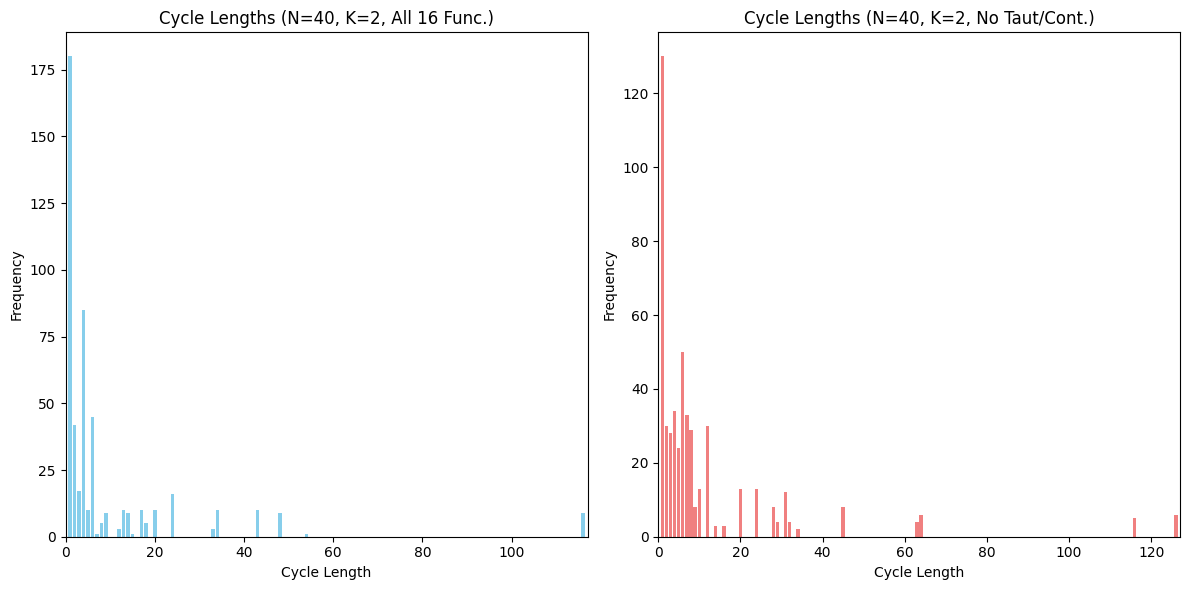


Stats for Fig 3a (All 16 functions, N=40):
  Number of cycles found: 500
  Mean cycle length: 9.31
  Median cycle length: 4.00
  Modal cycle length: 1 (occurs 180 times)

Stats for Fig 3b (No Taut/Cont, N=40):
  Number of cycles found: 500
  Mean cycle length: 11.51
  Median cycle length: 6.00
  Modal cycle length: 1 (occurs 130 times)


In [16]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter # For creating the histogram data easily

# --- Network Parameters ---
# For Figure 3a-like data
N_TARGET = 40 # Let's start smaller for a quick demo, then you can increase to 400
K = 2
NUM_NETWORK_INSTANCES = 50 # Number of different random networks to generate
NUM_INITIAL_STATES_PER_NET = 10 # Number of random initial states to test per network
MAX_SIMULATION_STEPS = N_TARGET * 50 # Max steps for each simulation run

# --- Boolean Functions for K=2 (all 16) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0], [0,0,0,1], [0,0,1,0], [0,0,1,1],
    [0,1,0,0], [0,1,0,1], [0,1,1,0], [0,1,1,1],
    [1,0,0,0], [1,0,0,1], [1,0,1,0], [1,0,1,1],
    [1,1,0,0], [1,1,0,1], [1,1,1,0], [1,1,1,1]
]

# --- Boolean Functions for K=2 (excluding Tautology [1,1,1,1] and Contradiction [0,0,0,0]) ---
BOOLEAN_FUNCTIONS_K2_NO_CONST = [f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]]
# len(BOOLEAN_FUNCTIONS_K2_NO_CONST) == 14

# --- Function to construct one network ---
def construct_network(N, K_val, boolean_function_set):
    genes_inputs = [[] for _ in range(N)]
    genes_functions = [[] for _ in range(N)]
    for i in range(N):
        possible_input_indices = [j for j in range(N) if j != i]
        if len(possible_input_indices) < K_val:
            input_indices = random.sample(range(N), K_val)
        else:
            input_indices = random.sample(possible_input_indices, K_val)
        genes_inputs[i] = input_indices
        genes_functions[i] = random.choice(boolean_function_set)
    return genes_inputs, genes_functions

# --- Function to simulate one run and find a cycle ---
def find_cycle_for_run(N, K_val, genes_inputs, genes_functions, initial_state, max_steps):
    genes_state = initial_state.copy()
    history_of_states = [list(genes_state)]
    found_cycle_len = -1 # Default if no cycle found

    for t in range(max_steps):
        next_genes_state_array = np.zeros(N, dtype=int)
        for i in range(N):
            input_values = [genes_state[genes_inputs[i][0]], genes_state[genes_inputs[i][1]]] # Assuming K=2
            if K_val == 2: # Specific logic for K=2
                in0_val, in1_val = input_values[0], input_values[1]
                if in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3
                gene_function = genes_functions[i]
                next_genes_state_array[i] = gene_function[truth_table_idx]
            else: # Placeholder for more general K
                pass # Implement general K lookup if needed

        genes_state = next_genes_state_array
        current_state_list = list(genes_state)

        if current_state_list in history_of_states:
            first_occurrence_index = history_of_states.index(current_state_list)
            found_cycle_len = len(history_of_states[first_occurrence_index:])
            break
        else:
            history_of_states.append(current_state_list)
            if len(history_of_states) > N*100 and N > 100 : # Memory guard for very large N if cycles are huge
                print(f"Warning: History too long for N={N}, run {len(history_of_states)}")
                break


    return found_cycle_len


# --- Main Simulation Loop to Collect Data ---
all_cycle_lengths_fig3a = []
all_cycle_lengths_fig3b = []

print(f"Simulating for Figure 3a type data (N={N_TARGET}, K={K}, all 16 functions)...")
for net_instance in range(NUM_NETWORK_INSTANCES):
    print(f"  Network instance {net_instance + 1}/{NUM_NETWORK_INSTANCES}")
    current_genes_inputs, current_genes_functions = construct_network(N_TARGET, K, BOOLEAN_FUNCTIONS_K2_ALL)

    # Store unique cycles found for this network instance to avoid double counting from different initial states leading to same cycle
    # (More rigorous would be to store the cycle states themselves, but for length histogram this is simpler)
    # cycles_found_this_net = set()

    for init_state_run in range(NUM_INITIAL_STATES_PER_NET):
        initial_s = np.random.randint(2, size=N_TARGET)
        cycle_len = find_cycle_for_run(N_TARGET, K, current_genes_inputs, current_genes_functions, initial_s, MAX_SIMULATION_STEPS)
        if cycle_len > 0:
            all_cycle_lengths_fig3a.append(cycle_len)
            # cycles_found_this_net.add(cycle_len) # If only counting unique cycle lengths *per net*
    # all_cycle_lengths_fig3a.extend(list(cycles_found_this_net))


print(f"\nSimulating for Figure 3b type data (N={N_TARGET}, K={K}, 14 functions - no Taut/Cont)...")
for net_instance in range(NUM_NETWORK_INSTANCES):
    print(f"  Network instance {net_instance + 1}/{NUM_NETWORK_INSTANCES}")
    current_genes_inputs, current_genes_functions = construct_network(N_TARGET, K, BOOLEAN_FUNCTIONS_K2_NO_CONST)
    # cycles_found_this_net = set()
    for init_state_run in range(NUM_INITIAL_STATES_PER_NET):
        initial_s = np.random.randint(2, size=N_TARGET)
        cycle_len = find_cycle_for_run(N_TARGET, K, current_genes_inputs, current_genes_functions, initial_s, MAX_SIMULATION_STEPS)
        if cycle_len > 0:
            all_cycle_lengths_fig3b.append(cycle_len)
            # cycles_found_this_net.add(cycle_len)
    # all_cycle_lengths_fig3b.extend(list(cycles_found_this_net))


# --- Plotting the Histograms ---
print("\nPlotting histograms...")

plt.figure(figsize=(12, 6))

# Histogram for Figure 3a data
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
if all_cycle_lengths_fig3a:
    # Calculate frequency for histogram
    counts_3a = Counter(all_cycle_lengths_fig3a)
    lengths_3a = sorted(counts_3a.keys())
    frequencies_3a = [counts_3a[l] for l in lengths_3a]
    plt.bar(lengths_3a, frequencies_3a, width=0.8, color='skyblue')
    # plt.hist(all_cycle_lengths_fig3a, bins=range(1, max(all_cycle_lengths_fig3a) + 2), align='left', rwidth=0.8)
    plt.title(f'Cycle Lengths (N={N_TARGET}, K={K}, All 16 Func.)')
    plt.xlabel('Cycle Length')
    plt.ylabel('Frequency')
    plt.xlim(0, max(lengths_3a if lengths_3a else [1]) + 1) # Adjust x-limit
else:
    plt.title(f'No cycles found for Fig 3a data (N={N_TARGET})')

# Histogram for Figure 3b data
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
if all_cycle_lengths_fig3b:
    counts_3b = Counter(all_cycle_lengths_fig3b)
    lengths_3b = sorted(counts_3b.keys())
    frequencies_3b = [counts_3b[l] for l in lengths_3b]
    plt.bar(lengths_3b, frequencies_3b, width=0.8, color='lightcoral')
    # plt.hist(all_cycle_lengths_fig3b, bins=range(1, max(all_cycle_lengths_fig3b) + 2), align='left', rwidth=0.8)
    plt.title(f'Cycle Lengths (N={N_TARGET}, K={K}, No Taut/Cont.)')
    plt.xlabel('Cycle Length')
    plt.ylabel('Frequency')
    plt.xlim(0, max(lengths_3b if lengths_3b else [1]) + 1) # Adjust x-limit

else:
    plt.title(f'No cycles found for Fig 3b data (N={N_TARGET})')

plt.tight_layout()
plt.show()

# Calculate and print some stats (optional)
if all_cycle_lengths_fig3a:
    print(f"\nStats for Fig 3a (All 16 functions, N={N_TARGET}):")
    print(f"  Number of cycles found: {len(all_cycle_lengths_fig3a)}")
    print(f"  Mean cycle length: {np.mean(all_cycle_lengths_fig3a):.2f}")
    print(f"  Median cycle length: {np.median(all_cycle_lengths_fig3a):.2f}")
    mode_3a = Counter(all_cycle_lengths_fig3a).most_common(1)
    if mode_3a: print(f"  Modal cycle length: {mode_3a[0][0]} (occurs {mode_3a[0][1]} times)")

if all_cycle_lengths_fig3b:
    print(f"\nStats for Fig 3b (No Taut/Cont, N={N_TARGET}):")
    print(f"  Number of cycles found: {len(all_cycle_lengths_fig3b)}")
    print(f"  Mean cycle length: {np.mean(all_cycle_lengths_fig3b):.2f}")
    print(f"  Median cycle length: {np.median(all_cycle_lengths_fig3b):.2f}")
    mode_3b = Counter(all_cycle_lengths_fig3b).most_common(1)
    if mode_3b: print(f"  Modal cycle length: {mode_3b[0][0]} (occurs {mode_3b[0][1]} times)")

Simulating for scatter plot data (N=40, K=2, No Taut/Cont)...
  Processing network instance 5/50 (No Taut/Cont)
  Processing network instance 10/50 (No Taut/Cont)
  Processing network instance 15/50 (No Taut/Cont)
  Processing network instance 20/50 (No Taut/Cont)
  Processing network instance 25/50 (No Taut/Cont)
  Processing network instance 30/50 (No Taut/Cont)
  Processing network instance 35/50 (No Taut/Cont)
  Processing network instance 40/50 (No Taut/Cont)
  Processing network instance 45/50 (No Taut/Cont)
  Processing network instance 50/50 (No Taut/Cont)

Plotting scatter plot (Y=Log(Run-in), X=Log(Cycle), No Taut/Cont)...


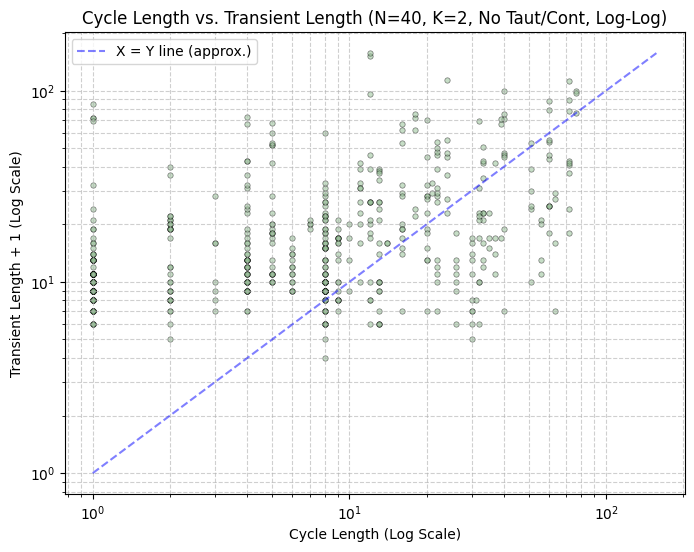


Pearson Correlation (No Taut/Cont, N=40): 0.406


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
# from collections import Counter # Not strictly needed for this specific scatter plot focus

# --- Network Parameters ---
N_TARGET = 40       # Number of genes (Kauffman mentions N=400 for Fig 5 context)
                    # Start smaller (e.g., 40) for faster testing, then increase.
K = 2               # Number of inputs per gene (fixed at 2)
NUM_NETWORK_INSTANCES = 50 # Number of different random networks to generate
NUM_INITIAL_STATES_PER_NET = 10 # Number of random initial states to test per network
MAX_SIMULATION_STEPS = N_TARGET * 100 # Max steps for each simulation run to find a cycle

# --- Boolean Functions for K=2 ---
# All 16 functions
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0], [0,0,0,1], [0,0,1,0], [0,0,1,1],
    [0,1,0,0], [0,1,0,1], [0,1,1,0], [0,1,1,1],
    [1,0,0,0], [1,0,0,1], [1,0,1,0], [1,0,1,1],
    [1,1,0,0], [1,1,0,1], [1,1,1,0], [1,1,1,1]
]

# 14 functions: excluding Tautology ([1,1,1,1]) and Contradiction ([0,0,0,0])
BOOLEAN_FUNCTIONS_K2_NO_CONST = [
    f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]
]

# --- Function to construct one network ---
def construct_network(N_genes, K_inputs, boolean_function_set):
    genes_inputs_list = [[] for _ in range(N_genes)]
    genes_functions_list = [[] for _ in range(N_genes)]
    for i in range(N_genes):
        possible_input_indices = [j for j in range(N_genes) if j != i]
        if len(possible_input_indices) < K_inputs:
            input_indices = random.sample(range(N_genes), K_inputs)
        else:
            input_indices = random.sample(possible_input_indices, K_inputs)
        genes_inputs_list[i] = input_indices
        genes_functions_list[i] = random.choice(boolean_function_set)
    return genes_inputs_list, genes_functions_list

# --- Function to simulate one run and find cycle & transient lengths ---
def find_cycle_and_transient_for_run(N_genes, K_inputs, current_genes_inputs, current_genes_functions, initial_state_np, max_steps_run):
    genes_state_np = initial_state_np.copy()
    history_of_states_list_of_lists = [list(genes_state_np)]

    cycle_len_found = -1
    transient_len_found = -1

    for t_step in range(max_steps_run):
        next_genes_state_array = np.zeros(N_genes, dtype=int)
        for i in range(N_genes):
            input_vals = [genes_state_np[current_genes_inputs[i][0]], genes_state_np[current_genes_inputs[i][1]]]
            if K_inputs == 2:
                in0_val, in1_val = input_vals[0], input_vals[1]
                if   in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3
                gene_func = current_genes_functions[i]
                next_genes_state_array[i] = gene_func[truth_table_idx]
            else:
                print("Error: This simulation is currently hardcoded for K=2 inputs.")
                return -1, -1

        genes_state_np = next_genes_state_array
        current_state_as_list = list(genes_state_np)

        try:
            first_occurrence_idx = history_of_states_list_of_lists.index(current_state_as_list)
            transient_len_found = first_occurrence_idx
            cycle_len_found = (t_step + 1) - first_occurrence_idx
            break
        except ValueError:
            history_of_states_list_of_lists.append(current_state_as_list)
            if t_step == max_steps_run - 1:
                pass

    return transient_len_found, cycle_len_found


# --- Main Simulation Loop to Collect Data for Scatter Plot ---
transient_cycle_pairs_data = []

print(f"Simulating for scatter plot data (N={N_TARGET}, K={K}, No Taut/Cont)...")
for net_idx in range(NUM_NETWORK_INSTANCES):
    if (net_idx + 1) % (NUM_NETWORK_INSTANCES // 10 or 1) == 0:
        print(f"  Processing network instance {net_idx + 1}/{NUM_NETWORK_INSTANCES} (No Taut/Cont)")

    genes_inputs, genes_functions = construct_network(N_TARGET, K, BOOLEAN_FUNCTIONS_K2_NO_CONST)

    for _ in range(NUM_INITIAL_STATES_PER_NET):
        initial_state_for_run = np.random.randint(2, size=N_TARGET)
        tr_len, cy_len = find_cycle_and_transient_for_run(
            N_TARGET, K, genes_inputs, genes_functions, initial_state_for_run, MAX_SIMULATION_STEPS
        )

        if tr_len != -1 and cy_len != -1:
            transient_cycle_pairs_data.append((tr_len, cy_len))

# --- Plotting the Scatter Plot (Y-axis = Log Run-in, X-axis = Log Cycle) ---
print("\nPlotting scatter plot (Y=Log(Run-in), X=Log(Cycle), No Taut/Cont)...")

if transient_cycle_pairs_data:
    # For plotting on log scale, values must be > 0.
    # Transient length can be 0. Cycle length is always >= 1.
    # Add 1 to transient lengths (Y-axis) to handle log(0).
    plot_transients_y = [pair[0] + 1 for pair in transient_cycle_pairs_data] # Y-axis data
    plot_cycles_x = [pair[1] for pair in transient_cycle_pairs_data]         # X-axis data

    if plot_transients_y and plot_cycles_x:
        plt.figure(figsize=(8, 6))
        # Swapped x and y in the scatter call
        plt.scatter(plot_cycles_x, plot_transients_y, alpha=0.5, s=15, color='darkseagreen', edgecolors='k', linewidths=0.5)

        plt.xscale('log') # X-axis is Cycle Length
        plt.yscale('log') # Y-axis is Transient Length + 1

        plt.title(f'Cycle Length vs. Transient Length (N={N_TARGET}, K={K}, No Taut/Cont, Log-Log)')
        plt.xlabel('Cycle Length (Log Scale)')      # X-axis label
        plt.ylabel('Transient Length + 1 (Log Scale)') # Y-axis label
        plt.grid(True, which="both", ls="--", alpha=0.6)

        min_val = min(min(plot_cycles_x if plot_cycles_x else [1]), min(plot_transients_y if plot_transients_y else [1]))
        max_val = max(max(plot_cycles_x if plot_cycles_x else [1]), max(plot_transients_y if plot_transients_y else [1]))
        if min_val > 0 and max_val > 0 and min_val < max_val :
             plt.plot([min_val, max_val], [min_val, max_val], 'b--', alpha=0.5, label='X = Y line (approx.)')
             plt.legend()

        plt.show()
    else:
        print("No valid data points (after adjustment for log scale) for log-log scatter plot.")
else:
    print("No (transient, cycle) pairs were collected to plot.")

# Optional: Calculate correlation on original collected data
if transient_cycle_pairs_data:
    original_transients = [pair[0] for pair in transient_cycle_pairs_data]
    original_cycles = [pair[1] for pair in transient_cycle_pairs_data]
    if len(original_transients) > 1 and len(original_cycles) > 1:
        correlation_matrix = np.corrcoef(original_transients, original_cycles) # Order of arrays doesn't matter for corrcoef
        if correlation_matrix.shape == (2,2):
            correlation = correlation_matrix[0, 1]
            print(f"\nPearson Correlation (No Taut/Cont, N={N_TARGET}): {correlation:.3f}")
        else:
            print("Could not compute correlation matrix properly.")
    elif len(original_transients) <=1 :
        print("Not enough data points to calculate correlation.")

In [7]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# --- Network Parameters ---
N_TARGET = 20       # Number of genes (start small for testing)
K = 2               # Number of inputs per gene
# For finding the number of cycles for ONE network instance:
NUM_INITIAL_STATES_TO_TEST = 50 # How many random initial states to try for this net
MAX_SIMULATION_STEPS = N_TARGET * 50 # Max steps for each run

# --- Boolean Functions (using the 14, as in Fig 6 description) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0], [0,0,0,1], [0,0,1,0], [0,0,1,1],
    [0,1,0,0], [0,1,0,1], [0,1,1,0], [0,1,1,1],
    [1,0,0,0], [1,0,0,1], [1,0,1,0], [1,0,1,1],
    [1,1,0,0], [1,1,0,1], [1,1,1,0], [1,1,1,1]
]
BOOLEAN_FUNCTIONS_K2_NO_CONST = [
    f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]
]
FUNCTION_SET_TO_USE = BOOLEAN_FUNCTIONS_K2_NO_CONST # As per Fig 6 description

# --- Function to construct one network (same as before) ---
def construct_network(N_genes, K_inputs, boolean_function_set):
    genes_inputs_list = [[] for _ in range(N_genes)]
    genes_functions_list = [[] for _ in range(N_genes)]
    for i in range(N_genes):
        possible_input_indices = [j for j in range(N_genes) if j != i]
        if len(possible_input_indices) < K_inputs:
            input_indices = random.sample(range(N_genes), K_inputs)
        else:
            input_indices = random.sample(possible_input_indices, K_inputs)
        genes_inputs_list[i] = input_indices
        genes_functions_list[i] = random.choice(boolean_function_set)
    return genes_inputs_list, genes_functions_list

# --- Function to simulate one run and return the canonical representation of the cycle states ---
def find_canonical_cycle_for_run(N_genes, K_inputs, current_genes_inputs, current_genes_functions, initial_state_np, max_steps_run):
    genes_state_np = initial_state_np.copy()
    history_of_states_list_of_lists = [list(genes_state_np)]

    canonical_cycle_representation = None # To store the found cycle

    for t_step in range(max_steps_run):
        next_genes_state_array = np.zeros(N_genes, dtype=int)
        for i in range(N_genes):
            input_vals = [genes_state_np[current_genes_inputs[i][0]], genes_state_np[current_genes_inputs[i][1]]]
            if K_inputs == 2:
                in0_val, in1_val = input_vals[0], input_vals[1]
                if   in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3
                gene_func = current_genes_functions[i]
                next_genes_state_array[i] = gene_func[truth_table_idx]
            else:
                return None # Error

        genes_state_np = next_genes_state_array
        current_state_as_list = list(genes_state_np)

        try:
            first_occurrence_idx = history_of_states_list_of_lists.index(current_state_as_list)
            cycle_states_list_of_lists = history_of_states_list_of_lists[first_occurrence_idx:]

            # Create a canonical representation for the cycle
            # Convert each state (list) in the cycle to a tuple to make it hashable
            # Then sort these state tuples and make the whole thing a tuple
            # This makes different starting points of the same cycle map to the same representation
            cycle_state_tuples = [tuple(s) for s in cycle_states_list_of_lists]
            canonical_cycle_representation = tuple(sorted(cycle_state_tuples))
            break
        except ValueError:
            history_of_states_list_of_lists.append(current_state_as_list)
            if t_step == max_steps_run - 1:
                # print(f"Warning: Max steps reached for N={N_genes}. No cycle found.")
                pass

    return canonical_cycle_representation

# --- Simulate for ONE network instance and find its number of distinct cycles ---
print(f"Constructing ONE network (N={N_TARGET}, K={K}, No Taut/Cont)...")
genes_inputs, genes_functions = construct_network(N_TARGET, K, FUNCTION_SET_TO_USE)

# Print network structure for this one instance (optional, can be verbose for large N)
# print("Network Structure for this instance:")
# for i in range(N_TARGET):
#     print(f"  Gene {i}: Inputs from {genes_inputs[i]}, Function: {genes_functions[i]}")
# print("-" * 30)

distinct_cycles_found_for_this_net = set() # Use a set to store unique canonical cycles

print(f"Running {NUM_INITIAL_STATES_TO_TEST} initial states for this network...")
for run_num in range(NUM_INITIAL_STATES_TO_TEST):
    if (run_num + 1) % (NUM_INITIAL_STATES_TO_TEST // 5 or 1) == 0:
        print(f"  Initial state run {run_num + 1}/{NUM_INITIAL_STATES_TO_TEST}")
    initial_state = np.random.randint(2, size=N_TARGET)

    canonical_cycle = find_canonical_cycle_for_run(
        N_TARGET, K, genes_inputs, genes_functions, initial_state, MAX_SIMULATION_STEPS
    )

    if canonical_cycle is not None:
        distinct_cycles_found_for_this_net.add(canonical_cycle)

number_of_distinct_cycles = len(distinct_cycles_found_for_this_net)
print("-" * 30)
print(f"For this ONE random network instance (N={N_TARGET}, K={K}, No Taut/Cont):")
print(f"Number of distinct behavior cycles found after {NUM_INITIAL_STATES_TO_TEST} initial states: {number_of_distinct_cycles}")

if distinct_cycles_found_for_this_net:
    print("Details of distinct cycles found:")
    for idx, cycle_repr in enumerate(distinct_cycles_found_for_this_net):
        cycle_length = len(cycle_repr)
        print(f"  Distinct Cycle {idx+1} (Length: {cycle_length}):")
        # For brevity, just print the first state of the canonical form
        # if cycle_repr: print(f"    Representative state: {list(cycle_repr[0])}")
        # Or print all states (can be long)
        # for state_tuple in cycle_repr:
        #    print(f"      {list(state_tuple)}")


# To generate data for Figure 6 (Histogram of Number of Cycles per Net):
# You would wrap the section "Simulate for ONE network instance..." in another loop
# that runs NUM_NETWORK_INSTANCES times.
# In that outer loop, you'd collect `number_of_distinct_cycles` from each network instance
# into a list, and then plot a histogram of that list.

# Example:
# counts_of_cycles_per_net = []
# NUM_NET_INSTANCES_FOR_HISTOGRAM = 100 # e.g.
# for net_idx in range(NUM_NET_INSTANCES_FOR_HISTOGRAM):
#     print(f"Processing Network Instance {net_idx+1} for histogram...")
#     # ... (repeat the code from "Constructing ONE network" down to getting number_of_distinct_cycles) ...
#     # genes_inputs, genes_functions = construct_network(N_TARGET, K, FUNCTION_SET_TO_USE)
#     # distinct_cycles_this_instance = set()
#     # for run_num in range(NUM_INITIAL_STATES_TO_TEST):
#     #     initial_state = np.random.randint(2, size=N_TARGET)
#     #     canonical_cycle = find_canonical_cycle_for_run(...)
#     #     if canonical_cycle: distinct_cycles_this_instance.add(canonical_cycle)
#     # counts_of_cycles_per_net.append(len(distinct_cycles_this_instance))

# # Then plot histogram of counts_of_cycles_per_net
# if counts_of_cycles_per_net:
#     plt.figure(figsize=(8,6))
#     hist_counts = Counter(counts_of_cycles_per_net)
#     x_vals = sorted(hist_counts.keys())
#     y_vals = [hist_counts[x] for x in x_vals]
#     plt.bar(x_vals, y_vals, color='dodgerblue', width=0.8)
#     plt.xlabel("Number of Distinct Cycles Found in a Net")
#     plt.ylabel("Frequency (Number of Nets)")
#     plt.title(f"Histogram of Cycles per Net (N={N_TARGET}, K={K}, No Taut/Cont)")
#     plt.xticks(x_vals) # Ensure ticks are at the actual counts
#     plt.grid(axis='y', linestyle='--', alpha=0.7)
#     plt.show()

#     print(f"\nStats for Number of Cycles per Net (N={N_TARGET}):")
#     print(f"  Mean cycles per net: {np.mean(counts_of_cycles_per_net):.2f}")
#     print(f"  Median cycles per net: {np.median(counts_of_cycles_per_net):.2f}")
#     mode_cycles = Counter(counts_of_cycles_per_net).most_common(1)
#     if mode_cycles: print(f"  Modal cycles per net: {mode_cycles[0][0]} (occurs {mode_cycles[0][1]} times)")

Constructing ONE network (N=20, K=2, No Taut/Cont)...
Running 50 initial states for this network...
  Initial state run 10/50
  Initial state run 20/50
  Initial state run 30/50
  Initial state run 40/50
  Initial state run 50/50
------------------------------
For this ONE random network instance (N=20, K=2, No Taut/Cont):
Number of distinct behavior cycles found after 50 initial states: 2
Details of distinct cycles found:
  Distinct Cycle 1 (Length: 3):
  Distinct Cycle 2 (Length: 15):



--- Simulating for: All 16 Boolean Functions ---
  Processing N = 10...
    N=10, Network instance 10/50
    N=10, Network instance 20/50
    N=10, Network instance 30/50
    N=10, Network instance 40/50
    N=10, Network instance 50/50
    N=10, Median Cycle Length = 2.00 (from 50 nets)
  Processing N = 20...
    N=20, Network instance 10/50
    N=20, Network instance 20/50
    N=20, Network instance 30/50
    N=20, Network instance 40/50
    N=20, Network instance 50/50
    N=20, Median Cycle Length = 3.00 (from 50 nets)
  Processing N = 40...
    N=40, Network instance 10/50
    N=40, Network instance 20/50
    N=40, Network instance 30/50
    N=40, Network instance 40/50
    N=40, Network instance 50/50
    N=40, Median Cycle Length = 4.00 (from 50 nets)
  Processing N = 80...
    N=80, Network instance 10/50
    N=80, Network instance 20/50
    N=80, Network instance 30/50
    N=80, Network instance 40/50
    N=80, Network instance 50/50
    N=80, Median Cycle Length = 4.00 (from

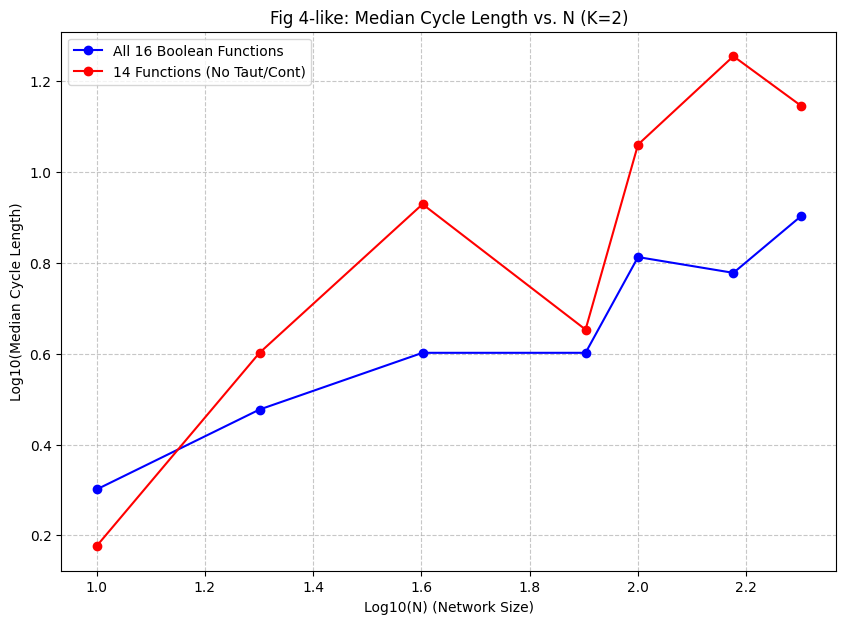

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# --- Reused Helper Functions (Assume these are defined as in your previous scripts) ---
# BOOLEAN_FUNCTIONS_K2_ALL, BOOLEAN_FUNCTIONS_K2_NO_CONST
# construct_network(N, K, boolean_function_set)
# find_cycle_for_run(N, K, genes_inputs, genes_functions, initial_state, max_steps)
# (find_cycle_for_run only needs to return cycle_length for this figure)

# --- START REUSED HELPER FUNCTIONS (Minimal for this script) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0],[0,0,0,1],[0,0,1,0],[0,0,1,1],[0,1,0,0],[0,1,0,1],[0,1,1,0],[0,1,1,1],
    [1,0,0,0],[1,0,0,1],[1,0,1,0],[1,0,1,1],[1,1,0,0],[1,1,0,1],[1,1,1,0],[1,1,1,1]
]
BOOLEAN_FUNCTIONS_K2_NO_CONST = [f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]]

def construct_network(N, K_val, boolean_function_set):
    genes_inputs = [[] for _ in range(N)]
    genes_functions = [[] for _ in range(N)]
    for i in range(N):
        possible_input_indices = [j for j in range(N) if j != i]
        if len(possible_input_indices) < K_val:
            input_indices = random.sample(range(N), K_val) # Allow self-loop if not enough others
        else:
            input_indices = random.sample(possible_input_indices, K_val)
        genes_inputs[i] = input_indices
        genes_functions[i] = random.choice(boolean_function_set)
    return genes_inputs, genes_functions

def find_cycle_for_run(N, K_val, genes_inputs, genes_functions, initial_state, max_steps):
    genes_state = initial_state.copy()
    history_of_states = [list(genes_state)]
    found_cycle_len = -1

    for _ in range(max_steps):
        next_genes_state_array = np.zeros(N, dtype=int)
        for i in range(N):
            if K_val == 2: # Specific K=2 logic
                input_vals_indices = genes_inputs[i]
                in0_val = genes_state[input_vals_indices[0]]
                in1_val = genes_state[input_vals_indices[1]]

                truth_table_idx = 0
                if in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3

                gene_function = genes_functions[i]
                next_genes_state_array[i] = gene_function[truth_table_idx]
            # Add logic for other K_val if needed

        genes_state = next_genes_state_array
        current_state_list = list(genes_state)

        if current_state_list in history_of_states:
            first_occurrence_index = history_of_states.index(current_state_list)
            found_cycle_len = len(history_of_states[first_occurrence_index:])
            break
        else:
            history_of_states.append(current_state_list)
            if len(history_of_states) > N * 100 and N > 100 : # Memory guard
                 # print(f"Warning: History too long for N={N}")
                 break
    return found_cycle_len # Only need cycle length
# --- END REUSED HELPER FUNCTIONS ---


# --- Simulation Parameters for Figure 4 ---
K = 2
# Kauffman uses N up to 8191. Let's use a smaller range for demo.
N_VALUES_FOR_FIG4 = [10, 20, 40, 80, 100, 150, 200] # Paper goes much higher
NUM_NETWORK_INSTANCES_PER_N = 50 # Paper: "at least 100 nets"
# NUM_INITIAL_STATES_PER_NET = 1 # Only need one cycle length per net for this stat
MAX_SIMULATION_STEPS_FACTOR = 50 # Max steps = N * FACTOR

# To store (N, median_cycle_length)
median_cycle_lengths_all_func = []
median_cycle_lengths_no_const = []

datasets_to_run = [
    {"name": "All 16 Boolean Functions", "functions": BOOLEAN_FUNCTIONS_K2_ALL, "results_list": median_cycle_lengths_all_func, "color": "blue"},
    {"name": "14 Functions (No Taut/Cont)", "functions": BOOLEAN_FUNCTIONS_K2_NO_CONST, "results_list": median_cycle_lengths_no_const, "color": "red"}
]

for dataset in datasets_to_run:
    print(f"\n--- Simulating for: {dataset['name']} ---")
    for N_current in N_VALUES_FOR_FIG4:
        print(f"  Processing N = {N_current}...")
        current_cycle_lengths_for_N = []
        MAX_STEPS = N_current * MAX_SIMULATION_STEPS_FACTOR
        for net_idx in range(NUM_NETWORK_INSTANCES_PER_N):
            if (net_idx + 1) % (NUM_NETWORK_INSTANCES_PER_N // 5 or 1) == 0:
                 print(f"    N={N_current}, Network instance {net_idx + 1}/{NUM_NETWORK_INSTANCES_PER_N}")

            genes_inputs, genes_functions = construct_network(N_current, K, dataset["functions"])
            initial_s = np.random.randint(2, size=N_current)

            cycle_len = find_cycle_for_run(N_current, K, genes_inputs, genes_functions, initial_s, MAX_STEPS)

            if cycle_len > 0:
                current_cycle_lengths_for_N.append(cycle_len)

        if current_cycle_lengths_for_N:
            median_len = np.median(current_cycle_lengths_for_N)
            dataset["results_list"].append((N_current, median_len))
            print(f"    N={N_current}, Median Cycle Length = {median_len:.2f} (from {len(current_cycle_lengths_for_N)} nets)")
        else:
            print(f"    N={N_current}, No cycles found to calculate median.")

# --- Plotting Figure 4 ---
plt.figure(figsize=(10, 7))
for dataset in datasets_to_run:
    if dataset["results_list"]:
        ns = [d[0] for d in dataset["results_list"]]
        lengths = [d[1] for d in dataset["results_list"]]
        # Filter out zero lengths for log plot if any somehow occurred
        plot_ns = [n for i, n in enumerate(ns) if lengths[i] > 0]
        plot_lengths = [l for l in lengths if l > 0]

        if plot_ns and plot_lengths:
            plt.plot(np.log10(plot_ns), np.log10(plot_lengths), marker='o', linestyle='-', label=dataset["name"], color=dataset["color"])

            # Optional: Fit line and calculate slope
            if len(plot_ns) >= 2:
                slope, intercept = np.polyfit(np.log10(plot_ns), np.log10(plot_lengths), 1)
                print(f"  Fitted slope for {dataset['name']}: {slope:.3f}")
                # Plot fitted line
                # fit_x = np.log10(plot_ns)
                # fit_y = slope * fit_x + intercept
                # plt.plot(fit_x, fit_y, '--', color=dataset["color"], alpha=0.7)


plt.xlabel("Log10(N) (Network Size)")
plt.ylabel("Log10(Median Cycle Length)")
plt.title(f"Fig 4-like: Median Cycle Length vs. N (K={K})")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.show()

Generating data for histogram (N=20, K=2, No Taut/Cont)...
Will create 100 network instances.
For each network, will test 30 initial states.
  Processing Network Instance 10/100 for histogram...
  Processing Network Instance 20/100 for histogram...
  Processing Network Instance 30/100 for histogram...
  Processing Network Instance 40/100 for histogram...
  Processing Network Instance 50/100 for histogram...
  Processing Network Instance 60/100 for histogram...
  Processing Network Instance 70/100 for histogram...
  Processing Network Instance 80/100 for histogram...
  Processing Network Instance 90/100 for histogram...
  Processing Network Instance 100/100 for histogram...
------------------------------
Plotting histogram of 'Number of Cycles per Net' (based on 100 networks)...


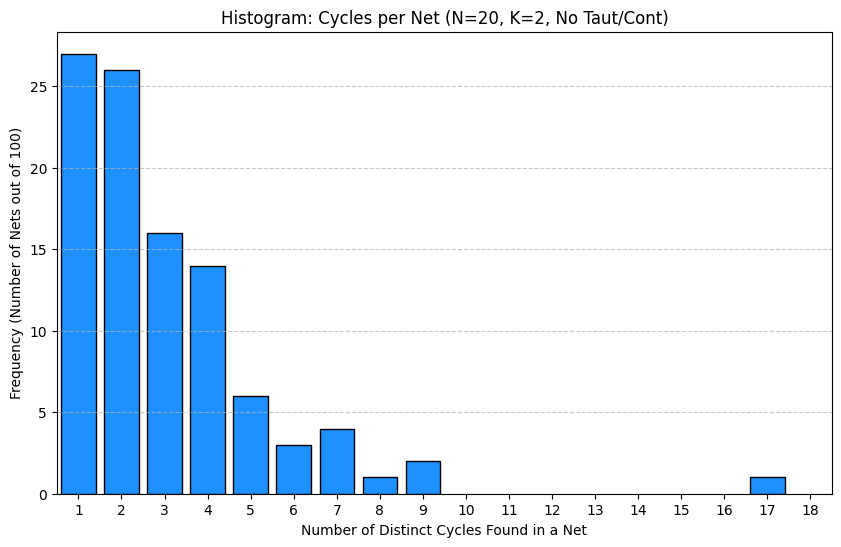

------------------------------
Statistics for 'Number of Cycles per Net' (N=20, K=2, No Taut/Cont):
  Based on 100 network instances.
  Mean cycles per net: 3.02
  Median cycles per net: 2.00
  Modal cycles per net: 1 (occurred in 27 nets)
  Min cycles found in a net: 1
  Max cycles found in a net: 17


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter # For easy histogram data generation

# --- Network Parameters ---
N_TARGET = 20       # Number of genes
K = 2               # Number of inputs per gene
NUM_INITIAL_STATES_PER_NET_INSTANCE = 30 # How many random initial states to try for EACH net
MAX_SIMULATION_STEPS_PER_RUN = N_TARGET * 50 # Max steps for each individual run

# For the histogram of "Number of Cycles per Net"
NUM_NETWORK_INSTANCES_FOR_HISTOGRAM = 100 # How many different random networks to generate

# --- Boolean Functions (using the 14, as in Fig 6 description) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0], [0,0,0,1], [0,0,1,0], [0,0,1,1],
    [0,1,0,0], [0,1,0,1], [0,1,1,0], [0,1,1,1],
    [1,0,0,0], [1,0,0,1], [1,0,1,0], [1,0,1,1],
    [1,1,0,0], [1,1,0,1], [1,1,1,0], [1,1,1,1]
]
BOOLEAN_FUNCTIONS_K2_NO_CONST = [
    f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]
]
FUNCTION_SET_TO_USE = BOOLEAN_FUNCTIONS_K2_NO_CONST

# --- Function to construct one network (same as before) ---
def construct_network(N_genes, K_inputs, boolean_function_set):
    genes_inputs_list = [[] for _ in range(N_genes)]
    genes_functions_list = [[] for _ in range(N_genes)]
    for i in range(N_genes):
        possible_input_indices = [j for j in range(N_genes) if j != i]
        if len(possible_input_indices) < K_inputs:
            input_indices = random.sample(range(N_genes), K_inputs)
        else:
            input_indices = random.sample(possible_input_indices, K_inputs)
        genes_inputs_list[i] = input_indices
        genes_functions_list[i] = random.choice(boolean_function_set)
    return genes_inputs_list, genes_functions_list

# --- Function to simulate one run and return the canonical cycle (same as before) ---
def find_canonical_cycle_for_run(N_genes, K_inputs, current_genes_inputs, current_genes_functions, initial_state_np, max_steps_run):
    genes_state_np = initial_state_np.copy()
    history_of_states_list_of_lists = [list(genes_state_np)]
    canonical_cycle_representation = None
    for t_step in range(max_steps_run):
        next_genes_state_array = np.zeros(N_genes, dtype=int)
        for i in range(N_genes):
            input_vals = [genes_state_np[current_genes_inputs[i][0]], genes_state_np[current_genes_inputs[i][1]]]
            if K_inputs == 2:
                in0_val, in1_val = input_vals[0], input_vals[1]
                if   in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3
                gene_func = current_genes_functions[i]
                next_genes_state_array[i] = gene_func[truth_table_idx]
            else: return None
        genes_state_np = next_genes_state_array
        current_state_as_list = list(genes_state_np)
        try:
            first_occurrence_idx = history_of_states_list_of_lists.index(current_state_as_list)
            cycle_states_list_of_lists = history_of_states_list_of_lists[first_occurrence_idx:]
            cycle_state_tuples = [tuple(s) for s in cycle_states_list_of_lists]
            canonical_cycle_representation = tuple(sorted(cycle_state_tuples))
            break
        except ValueError:
            history_of_states_list_of_lists.append(current_state_as_list)
            if t_step == max_steps_run - 1: pass
    return canonical_cycle_representation

# --- Main loop to generate data for the HISTOGRAM (Fig 6 like) ---
counts_of_cycles_per_net = [] # This will store the number of distinct cycles for each network instance

print(f"Generating data for histogram (N={N_TARGET}, K={K}, No Taut/Cont)...")
print(f"Will create {NUM_NETWORK_INSTANCES_FOR_HISTOGRAM} network instances.")
print(f"For each network, will test {NUM_INITIAL_STATES_PER_NET_INSTANCE} initial states.")

for net_idx in range(NUM_NETWORK_INSTANCES_FOR_HISTOGRAM):
    if (net_idx + 1) % (NUM_NETWORK_INSTANCES_FOR_HISTOGRAM // 10 or 1) == 0:
        print(f"  Processing Network Instance {net_idx + 1}/{NUM_NETWORK_INSTANCES_FOR_HISTOGRAM} for histogram...")

    # 1. Construct a NEW random network for this instance
    genes_inputs, genes_functions = construct_network(N_TARGET, K, FUNCTION_SET_TO_USE)

    distinct_cycles_this_instance = set() # To store unique cycles for THIS network instance

    # 2. Find distinct cycles for THIS network instance by running from multiple initial states
    for _ in range(NUM_INITIAL_STATES_PER_NET_INSTANCE):
        initial_state = np.random.randint(2, size=N_TARGET)
        canonical_cycle = find_canonical_cycle_for_run(
            N_TARGET, K, genes_inputs, genes_functions, initial_state, MAX_SIMULATION_STEPS_PER_RUN
        )
        if canonical_cycle is not None:
            distinct_cycles_this_instance.add(canonical_cycle)

    # 3. Store the count of distinct cycles found for this network instance
    counts_of_cycles_per_net.append(len(distinct_cycles_this_instance))

# --- Plotting the Histogram ---
print("-" * 30)
print(f"Plotting histogram of 'Number of Cycles per Net' (based on {NUM_NETWORK_INSTANCES_FOR_HISTOGRAM} networks)...")

if counts_of_cycles_per_net:
    plt.figure(figsize=(10,6))
    # Use Counter to get frequencies for each number of cycles
    cycle_counts_frequencies = Counter(counts_of_cycles_per_net)

    # Prepare data for bar plot
    x_values = sorted(cycle_counts_frequencies.keys()) # Number of cycles (1, 2, 3, ...)
    y_values = [cycle_counts_frequencies[x] for x in x_values] # How many nets had that many cycles

    plt.bar(x_values, y_values, color='dodgerblue', width=0.8, edgecolor='black')

    plt.xlabel("Number of Distinct Cycles Found in a Net")
    plt.ylabel(f"Frequency (Number of Nets out of {NUM_NETWORK_INSTANCES_FOR_HISTOGRAM})")
    plt.title(f"Histogram: Cycles per Net (N={N_TARGET}, K={K}, No Taut/Cont)")

    # Make sure x-ticks are integers and cover the range nicely
    if x_values:
        plt.xticks(range(min(x_values), max(x_values) + 2))
        plt.xlim(min(x_values) - 0.5, max(x_values) + 1.5)

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # --- Print Statistics for the "Number of Cycles per Net" distribution ---
    print("-" * 30)
    print(f"Statistics for 'Number of Cycles per Net' (N={N_TARGET}, K={K}, No Taut/Cont):")
    print(f"  Based on {len(counts_of_cycles_per_net)} network instances.")
    print(f"  Mean cycles per net: {np.mean(counts_of_cycles_per_net):.2f}")
    print(f"  Median cycles per net: {np.median(counts_of_cycles_per_net):.2f}")
    mode_info = Counter(counts_of_cycles_per_net).most_common(1)
    if mode_info:
        print(f"  Modal cycles per net: {mode_info[0][0]} (occurred in {mode_info[0][1]} nets)")
    print(f"  Min cycles found in a net: {min(counts_of_cycles_per_net)}")
    print(f"  Max cycles found in a net: {max(counts_of_cycles_per_net)}")
else:
    print("No data collected for the histogram (counts_of_cycles_per_net is empty).")

Generating data for Figure 7 (Log(Median Cycles) vs Log(N), K=2, No Taut/Cont)...

Processing for N = 10...
  N=10, Network instance 10/50
  N=10, Network instance 20/50
  N=10, Network instance 30/50
  N=10, Network instance 40/50
  N=10, Network instance 50/50
N=10, Median #Cycles/Net = 2.00 (from 50 nets)

Processing for N = 20...
  N=20, Network instance 10/50
  N=20, Network instance 20/50
  N=20, Network instance 30/50
  N=20, Network instance 40/50
  N=20, Network instance 50/50
N=20, Median #Cycles/Net = 2.00 (from 50 nets)

Processing for N = 40...
  N=40, Network instance 10/50
  N=40, Network instance 20/50
  N=40, Network instance 30/50
  N=40, Network instance 40/50
  N=40, Network instance 50/50
N=40, Median #Cycles/Net = 2.00 (from 50 nets)

Processing for N = 60...
  N=60, Network instance 10/50
  N=60, Network instance 20/50
  N=60, Network instance 30/50
  N=60, Network instance 40/50
  N=60, Network instance 50/50
N=60, Median #Cycles/Net = 3.00 (from 50 nets)

Proce

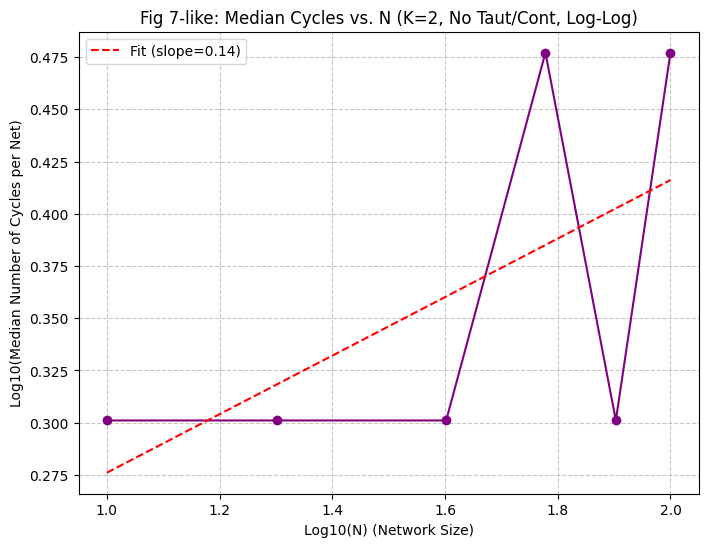

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# --- Simulation Parameters ---
K = 2               # Number of inputs per gene (fixed at 2)
# Define a list of N values to test for Figure 7
N_VALUES_FOR_FIG7 = [10, 20, 40, 60, 80, 100] # Add more N values for a better plot
                                            # e.g., up to 200 or more if patient
                                            # Kauffman went up to N=400 for Fig 6/7 data points

NUM_NETWORK_INSTANCES_PER_N = 50 # Number of different random networks for EACH N value
                                 # Kauffman used "at least 100" for some, 50 for others
NUM_INITIAL_STATES_PER_NET_INSTANCE = 20 # How many random initial states for EACH net
                                         # Kauffman used 50, then 20 for N > 200
MAX_SIMULATION_STEPS_PER_RUN = 0 # Will be set based on N_current later

# --- Boolean Functions (using the 14, as in Fig 6/7 description) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0], [0,0,0,1], [0,0,1,0], [0,0,1,1], [0,1,0,0], [0,1,0,1], [0,1,1,0], [0,1,1,1],
    [1,0,0,0], [1,0,0,1], [1,0,1,0], [1,0,1,1], [1,1,0,0], [1,1,0,1], [1,1,1,0], [1,1,1,1]
]
BOOLEAN_FUNCTIONS_K2_NO_CONST = [
    f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]
]
FUNCTION_SET_TO_USE = BOOLEAN_FUNCTIONS_K2_NO_CONST # As per Fig 6/7 description

# --- Helper Functions (construct_network, find_canonical_cycle_for_run - same as before) ---
def construct_network(N_genes, K_inputs, boolean_function_set):
    genes_inputs_list = [[] for _ in range(N_genes)]
    genes_functions_list = [[] for _ in range(N_genes)]
    for i in range(N_genes):
        possible_input_indices = [j for j in range(N_genes) if j != i]
        if len(possible_input_indices) < K_inputs:
            input_indices = random.sample(range(N_genes), K_inputs)
        else:
            input_indices = random.sample(possible_input_indices, K_inputs)
        genes_inputs_list[i] = input_indices
        genes_functions_list[i] = random.choice(boolean_function_set)
    return genes_inputs_list, genes_functions_list

def find_canonical_cycle_for_run(N_genes, K_inputs, current_genes_inputs, current_genes_functions, initial_state_np, max_steps_run):
    genes_state_np = initial_state_np.copy()
    history_of_states_list_of_lists = [list(genes_state_np)]
    canonical_cycle_representation = None
    for t_step in range(max_steps_run):
        next_genes_state_array = np.zeros(N_genes, dtype=int)
        for i in range(N_genes):
            input_vals = [genes_state_np[current_genes_inputs[i][0]], genes_state_np[current_genes_inputs[i][1]]]
            if K_inputs == 2:
                in0_val, in1_val = input_vals[0], input_vals[1]
                if   in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3
                gene_func = current_genes_functions[i]
                next_genes_state_array[i] = gene_func[truth_table_idx]
            else: return None
        genes_state_np = next_genes_state_array
        current_state_as_list = list(genes_state_np)
        try:
            first_occurrence_idx = history_of_states_list_of_lists.index(current_state_as_list)
            cycle_states_list_of_lists = history_of_states_list_of_lists[first_occurrence_idx:]
            cycle_state_tuples = [tuple(s) for s in cycle_states_list_of_lists]
            canonical_cycle_representation = tuple(sorted(cycle_state_tuples))
            break
        except ValueError:
            history_of_states_list_of_lists.append(current_state_as_list)
            if t_step == max_steps_run - 1: pass
    return canonical_cycle_representation

# --- Main Loop to Generate Data for Figure 7 (Log(Median Cycles) vs Log(N)) ---
median_cycles_per_N = [] # To store (N, median_num_cycles) pairs

print(f"Generating data for Figure 7 (Log(Median Cycles) vs Log(N), K={K}, No Taut/Cont)...")

for N_current in N_VALUES_FOR_FIG7:
    print(f"\nProcessing for N = {N_current}...")
    MAX_SIMULATION_STEPS_PER_RUN = N_current * 50 # Adjust max steps based on N

    counts_of_cycles_for_this_N = [] # Store num_distinct_cycles for all instances of THIS N

    for net_idx in range(NUM_NETWORK_INSTANCES_PER_N):
        if (net_idx + 1) % (NUM_NETWORK_INSTANCES_PER_N // 5 or 1) == 0: # Progress
            print(f"  N={N_current}, Network instance {net_idx + 1}/{NUM_NETWORK_INSTANCES_PER_N}")

        genes_inputs, genes_functions = construct_network(N_current, K, FUNCTION_SET_TO_USE)
        distinct_cycles_this_instance = set()

        for _ in range(NUM_INITIAL_STATES_PER_NET_INSTANCE):
            initial_state = np.random.randint(2, size=N_current)
            canonical_cycle = find_canonical_cycle_for_run(
                N_current, K, genes_inputs, genes_functions, initial_state, MAX_SIMULATION_STEPS_PER_RUN
            )
            if canonical_cycle is not None:
                distinct_cycles_this_instance.add(canonical_cycle)

        counts_of_cycles_for_this_N.append(len(distinct_cycles_this_instance))

    if counts_of_cycles_for_this_N:
        current_median_cycles = np.median(counts_of_cycles_for_this_N)
        median_cycles_per_N.append((N_current, current_median_cycles))
        print(f"N={N_current}, Median #Cycles/Net = {current_median_cycles:.2f} (from {len(counts_of_cycles_for_this_N)} nets)")
    else:
        print(f"N={N_current}, No data collected for median calculation.")


# --- Plotting Figure 7 (Log-Log Plot) ---
print("-" * 30)
print("Plotting Figure 7: Log(Median #Cycles/Net) vs Log(N)...")

if median_cycles_per_N:
    log_N_values = [np.log10(pair[0]) for pair in median_cycles_per_N]
    # Add 1 to median cycles before log if median can be 0, though unlikely for #cycles
    # However, #cycles can be 1, log10(1)=0. So direct log should be fine.
    # If a median was 0 (no cycles found consistently), that N point would be problematic for log.
    # Let's filter for medians > 0 for log plotting

    plot_data = [(pair[0], pair[1]) for pair in median_cycles_per_N if pair[1] > 0]
    if not plot_data:
        print("No data points with median cycles > 0 to plot.")
    else:
        log_N_plot = [np.log10(p[0]) for p in plot_data]
        log_median_cycles_plot = [np.log10(p[1]) for p in plot_data]

        plt.figure(figsize=(8,6))
        plt.plot(log_N_plot, log_median_cycles_plot, marker='o', linestyle='-', color='purple')

        plt.xlabel("Log10(N) (Network Size)")
        plt.ylabel("Log10(Median Number of Cycles per Net)")
        plt.title(f"Fig 7-like: Median Cycles vs. N (K={K}, No Taut/Cont, Log-Log)")
        plt.grid(True, which="both", ls="--", alpha=0.7)

        # Optional: Fit a line to estimate slope (if data looks linear)
        if len(log_N_plot) >= 2:
            # Perform linear regression: log_median_cycles = slope * log_N + intercept
            slope, intercept = np.polyfit(log_N_plot, log_median_cycles_plot, 1)
            print(f"\nFitted slope on log-log plot: {slope:.3f}")
            plt.plot(log_N_plot, slope * np.array(log_N_plot) + intercept, 'r--', label=f'Fit (slope={slope:.2f})')
            plt.legend()

        plt.show()
else:
    print("No median cycle data collected to plot Figure 7.")

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter # For potential histogramming if you add it back

# --- Simulation Parameters ---
K = 2               # Number of inputs per gene (fixed at 2)

# SUGGESTION: Extend N_VALUES and increase samples
N_VALUES_FOR_FIG7 = [10, 20, 40, 80, 160, 320, 400] # Extended range, more points
                                                # Kauffman used N up to 400 for these plots
                                                # Be aware: larger N takes much longer

NUM_NETWORK_INSTANCES_PER_N = 200 # SUGGESTION: Increased from 50/100. More is better.
                                  # This will significantly increase runtime.
NUM_INITIAL_STATES_PER_NET_INSTANCE = 50 # Kauffman found this was generally good.
MAX_SIMULATION_STEPS_PER_RUN = 0 # Will be set based on N_current later

# --- Boolean Functions (using the 14, as in Fig 6/7 description) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0], [0,0,0,1], [0,0,1,0], [0,0,1,1], [0,1,0,0], [0,1,0,1], [0,1,1,0], [0,1,1,1],
    [1,0,0,0], [1,0,0,1], [1,0,1,0], [1,0,1,1], [1,1,0,0], [1,1,0,1], [1,1,1,0], [1,1,1,1]
]
BOOLEAN_FUNCTIONS_K2_NO_CONST = [
    f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]
]
FUNCTION_SET_TO_USE = BOOLEAN_FUNCTIONS_K2_NO_CONST

# --- Helper Functions (construct_network, find_canonical_cycle_for_run - same as before) ---
def construct_network(N_genes, K_inputs, boolean_function_set):
    genes_inputs_list = [[] for _ in range(N_genes)]
    genes_functions_list = [[] for _ in range(N_genes)]
    for i in range(N_genes):
        possible_input_indices = [j for j in range(N_genes) if j != i]
        if len(possible_input_indices) < K_inputs:
            input_indices = random.sample(range(N_genes), K_inputs)
        else:
            input_indices = random.sample(possible_input_indices, K_inputs)
        genes_inputs_list[i] = input_indices
        genes_functions_list[i] = random.choice(boolean_function_set)
    return genes_inputs_list, genes_functions_list

def find_canonical_cycle_for_run(N_genes, K_inputs, current_genes_inputs, current_genes_functions, initial_state_np, max_steps_run):
    genes_state_np = initial_state_np.copy()
    history_of_states_list_of_lists = [list(genes_state_np)]
    canonical_cycle_representation = None
    for t_step in range(max_steps_run):
        next_genes_state_array = np.zeros(N_genes, dtype=int)
        for i in range(N_genes):
            input_vals = [genes_state_np[current_genes_inputs[i][0]], genes_state_np[current_genes_inputs[i][1]]]
            if K_inputs == 2:
                in0_val, in1_val = input_vals[0], input_vals[1]
                if   in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3
                gene_func = current_genes_functions[i]
                next_genes_state_array[i] = gene_func[truth_table_idx]
            else: return None
        genes_state_np = next_genes_state_array
        current_state_as_list = list(genes_state_np)
        try:
            first_occurrence_idx = history_of_states_list_of_lists.index(current_state_as_list)
            cycle_states_list_of_lists = history_of_states_list_of_lists[first_occurrence_idx:]
            cycle_state_tuples = [tuple(s) for s in cycle_states_list_of_lists]
            canonical_cycle_representation = tuple(sorted(cycle_state_tuples))
            break
        except ValueError:
            history_of_states_list_of_lists.append(current_state_as_list)
            if t_step == max_steps_run - 1: pass
    return canonical_cycle_representation

# --- Main Loop to Generate Data for Figure 7 (Log(Median Cycles) vs Log(N)) ---
median_cycles_per_N = []

print(f"Generating data for Figure 7 (Log(Median Cycles) vs Log(N), K={K}, No Taut/Cont)...")

for N_current in N_VALUES_FOR_FIG7:
    print(f"\nProcessing for N = {N_current}...")
    MAX_SIMULATION_STEPS_PER_RUN = N_current * 50 # Adjust max steps based on N

    counts_of_cycles_for_this_N = []

    for net_idx in range(NUM_NETWORK_INSTANCES_PER_N):
        if (net_idx + 1) % (NUM_NETWORK_INSTANCES_PER_N // 10 or 1) == 0:
            print(f"  N={N_current}, Network instance {net_idx + 1}/{NUM_NETWORK_INSTANCES_PER_N}")

        genes_inputs, genes_functions = construct_network(N_current, K, FUNCTION_SET_TO_USE)
        distinct_cycles_this_instance = set()

        for _ in range(NUM_INITIAL_STATES_PER_NET_INSTANCE):
            initial_state = np.random.randint(2, size=N_current)
            canonical_cycle = find_canonical_cycle_for_run(
                N_current, K, genes_inputs, genes_functions, initial_state, MAX_SIMULATION_STEPS_PER_RUN
            )
            if canonical_cycle is not None:
                distinct_cycles_this_instance.add(canonical_cycle)

        counts_of_cycles_for_this_N.append(len(distinct_cycles_this_instance))

    if counts_of_cycles_for_this_N:
        current_median_cycles = np.median(counts_of_cycles_for_this_N)
        # Ensure median is at least 1 for log plotting, though #cycles should be >=1 if any found
        if current_median_cycles < 1: current_median_cycles = 1.0
        median_cycles_per_N.append((N_current, current_median_cycles))
        print(f"N={N_current}, Median #Cycles/Net = {current_median_cycles:.2f} (from {len(counts_of_cycles_for_this_N)} nets)")
    else:
        print(f"N={N_current}, No data collected for median calculation.")


# --- Plotting Figure 7 (Log-Log Plot) ---
print("-" * 30)
print("Plotting Figure 7: Log(Median #Cycles/Net) vs Log(N)...")

if median_cycles_per_N:
    # Filter out any (N, median) pairs where median might be 0 if no cycles were ever found for an N
    # (though with enough runs, this is unlikely for #cycles which should be >=1)
    plot_data = [(pair[0], pair[1]) for pair in median_cycles_per_N if pair[1] > 0]

    if not plot_data:
        print("No data points with median cycles > 0 to plot for Figure 7.")
    else:
        log_N_plot = [np.log10(p[0]) for p in plot_data]
        log_median_cycles_plot = [np.log10(p[1]) for p in plot_data] # Median #cycles is >=1

        plt.figure(figsize=(10,7)) # Slightly larger figure
        plt.plot(log_N_plot, log_median_cycles_plot, marker='o', linestyle='-', color='purple', markersize=8, linewidth=2)

        plt.xlabel("Log10(N) (Network Size)", fontsize=12)
        plt.ylabel("Log10(Median Number of Cycles per Net)", fontsize=12)
        plt.title(f"Fig 7-like: Median Cycles vs. N (K={K}, No Taut/Cont, Log-Log)", fontsize=14)
        plt.grid(True, which="both", ls="--", alpha=0.7)
        plt.xticks(fontsize=10)
        plt.yticks(fontsize=10)

        # Perform linear regression to estimate slope
        if len(log_N_plot) >= 2:
            slope, intercept = np.polyfit(log_N_plot, log_median_cycles_plot, 1)
            print(f"\nFitted slope on log-log plot: {slope:.3f}")

            # Create points for the fitted line
            fit_line_x = np.array(log_N_plot) # Use existing log_N for x values of fit
            fit_line_y = slope * fit_line_x + intercept

            plt.plot(fit_line_x, fit_line_y, 'r--', linewidth=1.5, label=f'Fit (slope={slope:.2f})')

            # Optionally, plot a reference line with slope 0.5
            # To do this well, we need a sensible intercept for the reference
            # For y = 0.5x + c, pick c such that it goes through one of the data points or average
            # Or just plot an ideal line: y_ideal = 0.5 * x_ideal + some_intercept
            # For now, let's just show the actual fit.
            # If you want to add a perfect y = 0.5x line for comparison:
            # ideal_slope_line_y = 0.5 * fit_line_x + (np.mean(log_median_cycles_plot) - 0.5 * np.mean(log_N_plot)) # Centered
            # plt.plot(fit_line_x, ideal_slope_line_y, 'g:', label='Ideal slope=0.5 (approx.)')

            plt.legend(fontsize=10)

        plt.show()
else:
    print("No median cycle data collected to plot Figure 7.")

Generating data for Figure 7 (Log(Median Cycles) vs Log(N), K=2, No Taut/Cont)...

Processing for N = 10...
  N=10, Network instance 20/200
  N=10, Network instance 40/200
  N=10, Network instance 60/200
  N=10, Network instance 80/200
  N=10, Network instance 100/200
  N=10, Network instance 120/200
  N=10, Network instance 140/200
  N=10, Network instance 160/200
  N=10, Network instance 180/200
  N=10, Network instance 200/200
N=10, Median #Cycles/Net = 2.00 (from 200 nets)

Processing for N = 20...
  N=20, Network instance 20/200
  N=20, Network instance 40/200
  N=20, Network instance 60/200
  N=20, Network instance 80/200
  N=20, Network instance 100/200
  N=20, Network instance 120/200
  N=20, Network instance 140/200
  N=20, Network instance 160/200
  N=20, Network instance 180/200
  N=20, Network instance 200/200
N=20, Median #Cycles/Net = 2.00 (from 200 nets)

Processing for N = 40...
  N=40, Network instance 20/200
  N=40, Network instance 40/200
  N=40, Network instance 60/

--- Simulating for Figure 8 (N=100, K=2) ---
  Processing Network 1/30...
    Net 1: Min dist between cycles = 1, Ref Cycle Len = 8
  Processing Network 2/30...
    Found 1 cycle(s). Need at least 2 for distance calc. Skipping.
  Processing Network 3/30...
    Net 3: Min dist between cycles = 3, Ref Cycle Len = 4
  Processing Network 4/30...
    Net 4: Min dist between cycles = 1, Ref Cycle Len = 18
  Processing Network 5/30...
    Found 1 cycle(s). Need at least 2 for distance calc. Skipping.
  Processing Network 6/30...
    Found 1 cycle(s). Need at least 2 for distance calc. Skipping.
  Processing Network 7/30...
    Net 7: Min dist between cycles = 2, Ref Cycle Len = 4
  Processing Network 8/30...
    Net 8: Min dist between cycles = 2, Ref Cycle Len = 12
  Processing Network 9/30...
    Net 9: Min dist between cycles = 2, Ref Cycle Len = 1
  Processing Network 10/30...
    Found 1 cycle(s). Need at least 2 for distance calc. Skipping.
  Processing Network 11/30...
    Net 11: Min 

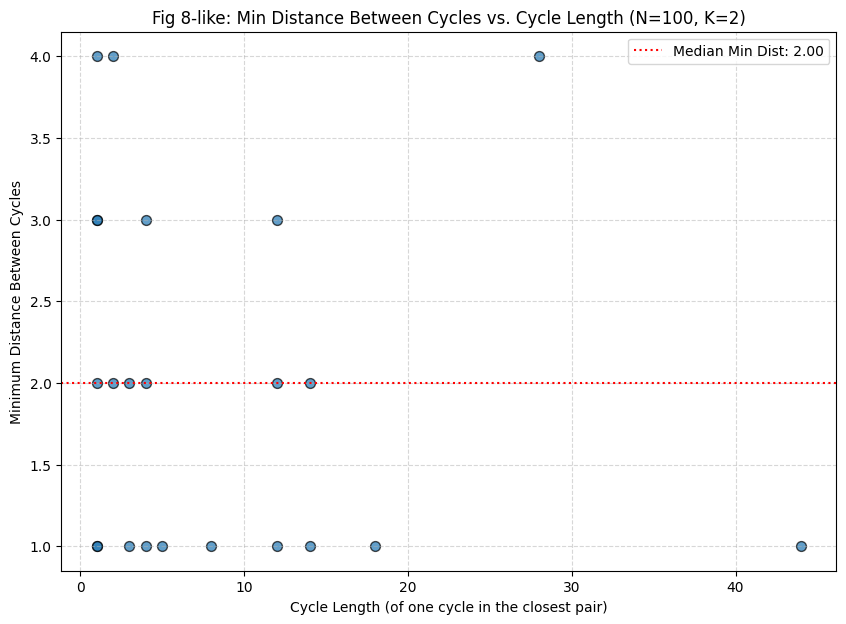

In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import itertools # For combinations

# --- Reused Helper Functions ---
# BOOLEAN_FUNCTIONS_K2_ALL
# construct_network(N, K, boolean_function_set)
# find_canonical_cycle_for_run(N, K, genes_inputs, genes_functions, initial_state, max_steps)
# (This now needs to return the canonical cycle representation for comparison)

# --- START REUSED HELPER FUNCTIONS (Modified find_canonical_cycle_for_run) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0],[0,0,0,1],[0,0,1,0],[0,0,1,1],[0,1,0,0],[0,1,0,1],[0,1,1,0],[0,1,1,1],
    [1,0,0,0],[1,0,0,1],[1,0,1,0],[1,0,1,1],[1,1,0,0],[1,1,0,1],[1,1,1,0],[1,1,1,1]
]

def construct_network(N, K_val, boolean_function_set): # Same as before
    genes_inputs = [[] for _ in range(N)]
    genes_functions = [[] for _ in range(N)]
    for i in range(N):
        possible_input_indices = [j for j in range(N) if j != i]
        if len(possible_input_indices) < K_val:
            input_indices = random.sample(range(N), K_val)
        else:
            input_indices = random.sample(possible_input_indices, K_val)
        genes_inputs[i] = input_indices
        genes_functions[i] = random.choice(boolean_function_set)
    return genes_inputs, genes_functions

def find_canonical_cycle_for_run(N, K_val, genes_inputs, genes_functions, initial_state, max_steps):
    genes_state = initial_state.copy()
    history_of_states = [list(genes_state)]
    canonical_cycle_representation = None

    for t_step in range(max_steps):
        next_genes_state_array = np.zeros(N, dtype=int)
        for i in range(N):
            if K_val == 2:
                input_vals_indices = genes_inputs[i]
                in0_val = genes_state[input_vals_indices[0]]
                in1_val = genes_state[input_vals_indices[1]]
                truth_table_idx = (in0_val * 2) + in1_val # Simplified
                gene_function = genes_functions[i]
                next_genes_state_array[i] = gene_function[truth_table_idx]
            # Add logic for other K_val if needed

        genes_state = next_genes_state_array
        current_state_list = list(genes_state)

        if current_state_list in history_of_states:
            first_occurrence_idx = history_of_states.index(current_state_list)
            cycle_states_list_of_lists = history_of_states[first_occurrence_idx:]

            # Create canonical representation
            cycle_state_tuples = [tuple(s) for s in cycle_states_list_of_lists]
            # Find the lexicographically smallest tuple in all cyclic shifts
            min_tuple_cycle = min(cycle_state_tuples[i:] + cycle_state_tuples[:i] for i in range(len(cycle_state_tuples)))
            canonical_cycle_representation = tuple(min_tuple_cycle) # A tuple of tuples
            break
        else:
            history_of_states.append(current_state_list)
            if len(history_of_states) > N * 100 and N > 50 :
                # print(f"Warning: History too long for N={N}")
                break
    return canonical_cycle_representation
# --- END REUSED HELPER FUNCTIONS ---

def hamming_distance(s1, s2):
    # s1, s2 are tuples or lists of 0s and 1s
    return sum(el1 != el2 for el1, el2 in zip(s1, s2))

# --- Simulation Parameters for Figure 8 ---
N_TARGET = 100 # As in paper
K = 2
BOOLEAN_FUNCTION_SET = BOOLEAN_FUNCTIONS_K2_ALL
NUM_NETWORKS_FIG8 = 30 # Collect a few dozen points for scatter
NUM_INITIAL_STATES_FOR_CYCLES = N_TARGET * 2 # To find distinct cycles for ONE net
MAX_SIMULATION_STEPS = N_TARGET * 50

fig8_data = [] # To store (cycle_length_ref, min_distance_to_other_cycle)

print(f"--- Simulating for Figure 8 (N={N_TARGET}, K={K}) ---")
for net_idx in range(NUM_NETWORKS_FIG8):
    print(f"  Processing Network {net_idx + 1}/{NUM_NETWORKS_FIG8}...")
    genes_inputs, genes_functions = construct_network(N_TARGET, K, BOOLEAN_FUNCTION_SET)

    distinct_cycles_found = set()
    for _ in range(NUM_INITIAL_STATES_FOR_CYCLES):
        initial_s = np.random.randint(2, size=N_TARGET)
        cycle_repr = find_canonical_cycle_for_run(N_TARGET, K, genes_inputs, genes_functions, initial_s, MAX_SIMULATION_STEPS)
        if cycle_repr:
            distinct_cycles_found.add(cycle_repr)

    if len(distinct_cycles_found) < 2:
        print(f"    Found {len(distinct_cycles_found)} cycle(s). Need at least 2 for distance calc. Skipping.")
        continue

    cycles_list = list(distinct_cycles_found)
    min_dist_for_net = float('inf')
    ref_cycle_len_for_min_dist = -1

    # Iterate over all unique pairs of cycles
    for cycle_A_idx, cycle_B_idx in itertools.combinations(range(len(cycles_list)), 2):
        cycle_A = cycles_list[cycle_A_idx] # cycle_A is a tuple of state_tuples
        cycle_B = cycles_list[cycle_B_idx]

        current_min_pair_dist = float('inf')
        # Find min Hamming distance between any state in A and any state in B
        for state_A in cycle_A: # state_A is a state_tuple
            for state_B in cycle_B:
                dist = hamming_distance(state_A, state_B)
                current_min_pair_dist = min(current_min_pair_dist, dist)

        if current_min_pair_dist < min_dist_for_net:
            min_dist_for_net = current_min_pair_dist
            # Use length of shorter cycle of the pair as reference
            ref_cycle_len_for_min_dist = min(len(cycle_A), len(cycle_B))

    if min_dist_for_net != float('inf'):
        fig8_data.append((ref_cycle_len_for_min_dist, min_dist_for_net))
        print(f"    Net {net_idx+1}: Min dist between cycles = {min_dist_for_net}, Ref Cycle Len = {ref_cycle_len_for_min_dist}")

# --- Plotting Figure 8 ---
if fig8_data:
    cycle_lengths_x = [d[0] for d in fig8_data if d[0] > 0] # Ensure positive cycle lengths
    min_distances_y = [d[1] for i, d in enumerate(fig8_data) if fig8_data[i][0] > 0]

    if cycle_lengths_x: # Check if there's anything to plot
        plt.figure(figsize=(10, 7))
        plt.scatter(cycle_lengths_x, min_distances_y, alpha=0.7, edgecolors='k', s=50)

        plt.xlabel("Cycle Length (of one cycle in the closest pair)")
        plt.ylabel("Minimum Distance Between Cycles")
        plt.title(f"Fig 8-like: Min Distance Between Cycles vs. Cycle Length (N={N_TARGET}, K={K})")
        # plt.xscale('log') # Paper's x-axis is not log, but y-axis values are small
        # plt.yscale('log') # Paper's y-axis is not log either
        plt.grid(True, linestyle='--', alpha=0.5)

        median_min_dist = np.median(min_distances_y)
        print(f"\nMedian minimum distance found: {median_min_dist:.2f} (Paper: {0.05*N_TARGET})")
        plt.axhline(median_min_dist, color='r', linestyle=':', label=f'Median Min Dist: {median_min_dist:.2f}')
        plt.legend()
        plt.show()
    else:
        print("No valid data (positive cycle lengths) to plot for Fig 8.")
else:
    print("No data collected for Figure 8.")

Generating data for Figure 9 (N=30, K=2, No Taut/Cont)...
Will create 10 network instances.

Processing Network Instance 1/10...
  Discovering attractors for this network...
  Found 1 distinct attractor(s) for this network.
    Perturbing attractor 1/1 (length 4)...

Processing Network Instance 2/10...
  Discovering attractors for this network...
  Found 3 distinct attractor(s) for this network.
    Perturbing attractor 1/3 (length 22)...
    Perturbing attractor 2/3 (length 34)...
    Perturbing attractor 3/3 (length 13)...

Processing Network Instance 3/10...
  Discovering attractors for this network...
  Found 2 distinct attractor(s) for this network.
    Perturbing attractor 1/2 (length 10)...
    Perturbing attractor 2/2 (length 12)...

Processing Network Instance 4/10...
  Discovering attractors for this network...
  Found 8 distinct attractor(s) for this network.
    Perturbing attractor 1/8 (length 9)...
    Perturbing attractor 2/8 (length 9)...
    Perturbing attractor 3/8 (l

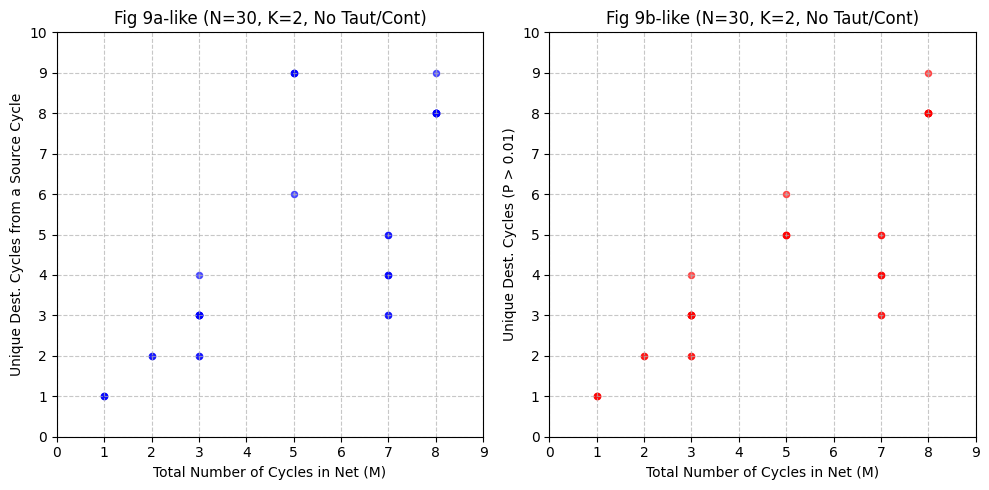

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

# --- Network Parameters ---
# For Figure 9 data, Kauffman used N=191 and N=400
# Let's use a smaller N for a quicker demo.
N_TARGET = 30  # Number of genes
K = 2
FUNCTION_SET_NAME = "No Taut/Cont" # For titles

NUM_NETWORK_INSTANCES_FOR_FIG9 = 10 # How many different random networks to generate (LOW FOR DEMO)
NUM_INITIAL_STATES_FOR_CYCLE_DISCOVERY = 30 # To find the cycles within one net
MAX_SIMULATION_STEPS_PER_RUN = N_TARGET * 50

# --- Boolean Functions (using the 14, No Taut/Cont) ---
BOOLEAN_FUNCTIONS_K2_ALL = [
    [0,0,0,0], [0,0,0,1], [0,0,1,0], [0,0,1,1], [0,1,0,0], [0,1,0,1], [0,1,1,0], [0,1,1,1],
    [1,0,0,0], [1,0,0,1], [1,0,1,0], [1,0,1,1], [1,1,0,0], [1,1,0,1], [1,1,1,0], [1,1,1,1]
]
BOOLEAN_FUNCTIONS_K2_NO_CONST = [
    f for f in BOOLEAN_FUNCTIONS_K2_ALL if f != [0,0,0,0] and f != [1,1,1,1]
]
FUNCTION_SET_TO_USE = BOOLEAN_FUNCTIONS_K2_NO_CONST

# --- Helper Functions (construct_network, find_canonical_cycle_for_run - same as before) ---
def construct_network(N_genes, K_inputs, boolean_function_set):
    # ... (same as previous script)
    genes_inputs_list = [[] for _ in range(N_genes)]
    genes_functions_list = [[] for _ in range(N_genes)]
    for i in range(N_genes):
        possible_input_indices = [j for j in range(N_genes) if j != i]
        if len(possible_input_indices) < K_inputs:
            input_indices = random.sample(range(N_genes), K_inputs)
        else:
            input_indices = random.sample(possible_input_indices, K_inputs)
        genes_inputs_list[i] = input_indices
        genes_functions_list[i] = random.choice(boolean_function_set)
    return genes_inputs_list, genes_functions_list

def find_canonical_cycle_from_state(N_genes, K_inputs, current_genes_inputs, current_genes_functions, initial_state_np, max_steps_run):
    # ... (same as find_canonical_cycle_for_run, renamed for clarity)
    genes_state_np = initial_state_np.copy()
    history_of_states_list_of_lists = [list(genes_state_np)]
    canonical_cycle_representation = None
    for t_step in range(max_steps_run):
        next_genes_state_array = np.zeros(N_genes, dtype=int)
        for i in range(N_genes):
            input_vals = [genes_state_np[current_genes_inputs[i][0]], genes_state_np[current_genes_inputs[i][1]]]
            if K_inputs == 2:
                in0_val, in1_val = input_vals[0], input_vals[1]
                if   in0_val == 0 and in1_val == 0: truth_table_idx = 0
                elif in0_val == 0 and in1_val == 1: truth_table_idx = 1
                elif in0_val == 1 and in1_val == 0: truth_table_idx = 2
                else: truth_table_idx = 3
                gene_func = current_genes_functions[i]
                next_genes_state_array[i] = gene_func[truth_table_idx]
            else: return None
        genes_state_np = next_genes_state_array
        current_state_as_list = list(genes_state_np)
        try:
            first_occurrence_idx = history_of_states_list_of_lists.index(current_state_as_list)
            cycle_states_list_of_lists = history_of_states_list_of_lists[first_occurrence_idx:]
            cycle_state_tuples = [tuple(s) for s in cycle_states_list_of_lists]
            canonical_cycle_representation = tuple(sorted(cycle_state_tuples)) # The cycle itself
            break
        except ValueError:
            history_of_states_list_of_lists.append(current_state_as_list)
            if t_step == max_steps_run - 1: pass
    return canonical_cycle_representation


# --- Main Data Collection Loop for Figure 9 ---
data_for_fig9a = [] # Store tuples: (total_cycles_in_net, unique_dest_cycles_from_source_cycle)
data_for_fig9b = [] # Store tuples: (total_cycles_in_net, unique_dest_cycles_with_P_gt_0.01)

print(f"Generating data for Figure 9 (N={N_TARGET}, K={K}, {FUNCTION_SET_NAME})...")
print(f"Will create {NUM_NETWORK_INSTANCES_FOR_FIG9} network instances.")

for net_idx in range(NUM_NETWORK_INSTANCES_FOR_FIG9):
    print(f"\nProcessing Network Instance {net_idx + 1}/{NUM_NETWORK_INSTANCES_FOR_FIG9}...")

    # 1. Construct Network
    genes_inputs, genes_functions = construct_network(N_TARGET, K, FUNCTION_SET_TO_USE)

    # 2. Find All Its Distinct Cycles (Attractors)
    print("  Discovering attractors for this network...")
    distinct_attractors_in_net = set()
    for _ in range(NUM_INITIAL_STATES_FOR_CYCLE_DISCOVERY):
        initial_state = np.random.randint(2, size=N_TARGET)
        attractor = find_canonical_cycle_from_state(
            N_TARGET, K, genes_inputs, genes_functions, initial_state, MAX_SIMULATION_STEPS_PER_RUN
        )
        if attractor is not None:
            distinct_attractors_in_net.add(attractor)

    total_cycles_M_in_this_net = len(distinct_attractors_in_net)
    if total_cycles_M_in_this_net == 0:
        print("  No attractors found for this network instance. Skipping perturbation analysis.")
        continue
    print(f"  Found {total_cycles_M_in_this_net} distinct attractor(s) for this network.")

    # Convert set of attractors to a list for indexed access
    attractors_list = list(distinct_attractors_in_net)

    # 3. For EACH attractor (source_cycle), perform perturbation analysis
    for source_cycle_idx, source_cycle_canonical in enumerate(attractors_list):
        print(f"    Perturbing attractor {source_cycle_idx + 1}/{total_cycles_M_in_this_net} (length {len(source_cycle_canonical)})...")

        # source_cycle_canonical is tuple of sorted state_tuples
        # To get actual states for perturbation, we need one of its orderings
        # For simplicity, just take the states as they are in the sorted tuple representation
        # This isn't strictly "traversing the cycle" but perturbing each unique state OF the cycle

        destination_cycle_counts = Counter() # Counts transitions to each destination attractor
        total_perturbations_for_this_source = 0

        for state_tuple_in_source_cycle in source_cycle_canonical:
            original_state_array = np.array(state_tuple_in_source_cycle)
            for gene_to_flip in range(N_TARGET):
                perturbed_state_array = original_state_array.copy()
                perturbed_state_array[gene_to_flip] = 1 - perturbed_state_array[gene_to_flip] # Flip the bit
                total_perturbations_for_this_source += 1

                # Find where this perturbed state leads
                dest_attractor = find_canonical_cycle_from_state(
                    N_TARGET, K, genes_inputs, genes_functions, perturbed_state_array, MAX_SIMULATION_STEPS_PER_RUN
                )
                if dest_attractor is not None:
                    destination_cycle_counts[dest_attractor] += 1

        # Analyze results for this source_cycle
        if total_perturbations_for_this_source > 0:
            # For Fig 9a: total number of unique destination cycles reached
            num_unique_dest_cycles_9a = len(destination_cycle_counts)
            data_for_fig9a.append((total_cycles_M_in_this_net, num_unique_dest_cycles_9a))

            # For Fig 9b: number of unique destination cycles reached with P > 0.01
            num_unique_dest_cycles_9b = 0
            for dest_attractor_key, count in destination_cycle_counts.items():
                probability = count / total_perturbations_for_this_source
                if probability > 0.01:
                    num_unique_dest_cycles_9b += 1
            data_for_fig9b.append((total_cycles_M_in_this_net, num_unique_dest_cycles_9b))


# --- Plotting Figure 9a ---
print("\nPlotting Figure 9a data...")
if data_for_fig9a:
    x_9a = [pair[0] for pair in data_for_fig9a] # Total cycles in net (M)
    y_9a = [pair[1] for pair in data_for_fig9a] # Unique destinations from a source cycle

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.scatter(x_9a, y_9a, alpha=0.6, s=20, color='blue')
    plt.xlabel("Total Number of Cycles in Net (M)")
    plt.ylabel("Unique Dest. Cycles from a Source Cycle")
    plt.title(f"Fig 9a-like (N={N_TARGET}, K={K}, {FUNCTION_SET_NAME})")
    plt.grid(True, linestyle='--', alpha=0.7)
    if x_9a and y_9a: # Set limits based on data
        plt.xlim(0, max(x_9a) + 1 if x_9a else 10)
        plt.ylim(0, max(y_9a) + 1 if y_9a else 10)
        # Add ticks for integer values if appropriate
        if max(x_9a) < 20 : plt.xticks(range(0, max(x_9a)+2, 1 if max(x_9a) < 10 else 2 ))
        if max(y_9a) < 20 : plt.yticks(range(0, max(y_9a)+2, 1 if max(y_9a) < 10 else 2 ))


# --- Plotting Figure 9b ---
    print("Plotting Figure 9b data...")
    plt.subplot(1, 2, 2)
    if data_for_fig9b:
        x_9b = [pair[0] for pair in data_for_fig9b] # Total cycles in net (M)
        y_9b = [pair[1] for pair in data_for_fig9b] # Unique destinations with P > 0.01

        plt.scatter(x_9b, y_9b, alpha=0.6, s=20, color='red')
        plt.xlabel("Total Number of Cycles in Net (M)")
        plt.ylabel("Unique Dest. Cycles (P > 0.01)")
        plt.title(f"Fig 9b-like (N={N_TARGET}, K={K}, {FUNCTION_SET_NAME})")
        plt.grid(True, linestyle='--', alpha=0.7)
        if x_9b and y_9b: # Set limits based on data
            plt.xlim(0, max(x_9b) + 1 if x_9b else 10)
            plt.ylim(0, max(y_9b) + 1 if y_9b else 10)
            if max(x_9b) < 20 : plt.xticks(range(0, max(x_9b)+2, 1 if max(x_9b) < 10 else 2 ))
            if max(y_9b) < 20 : plt.yticks(range(0, max(y_9b)+2, 1 if max(y_9b) < 10 else 2 ))


    plt.tight_layout()
    plt.show()
else:
    print("No data collected to plot Figure 9.")

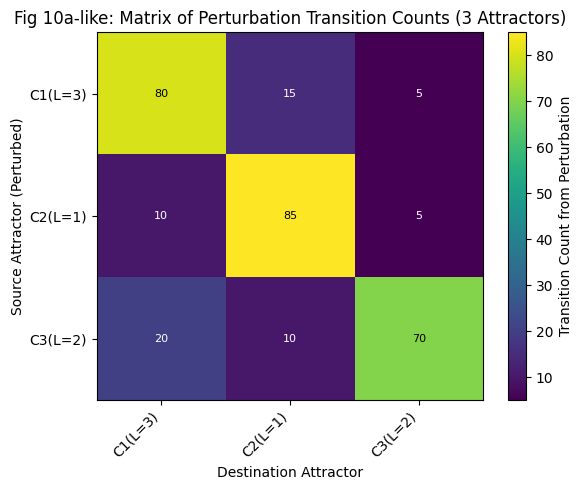

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter # If all_source_dest_counts_fig10a is a list of Counters

# --- ASSUME THESE VARIABLES ARE PRE-POPULATED FROM A FIG 9 SIMULATION OF ONE NET ---
# Example:
# c1_repr = ((0,0,1),(0,1,0),(1,0,0)) # Canonical representation of cycle 1
# c2_repr = ((1,1,1),)                # Canonical representation of cycle 2
# c3_repr = ((0,0,0),(1,1,0))        # Canonical representation of cycle 3
# attractors_list_fig10a = [c1_repr, c2_repr, c3_repr]
# # all_source_dest_counts_fig10a is a list of dictionaries or Counters.
# # all_source_dest_counts_fig10a[i] stores the destination counts from perturbing source attractor i.
# # Keys in the inner dict/Counter are canonical representations of destination attractors.
# all_source_dest_counts_fig10a = [
#     Counter({c1_repr: 80, c2_repr: 15, c3_repr: 5}),  # Transitions from c1
#     Counter({c1_repr: 10, c2_repr: 85, c3_repr: 5}),  # Transitions from c2
#     Counter({c1_repr: 20, c2_repr: 10, c3_repr: 70})  # Transitions from c3
# ]

# --- START: Placeholder data (if not from actual Fig 9 run) ---
if 'attractors_list_fig10a' not in globals():
    print("Warning: Using placeholder data for Fig 10a.")
    # Placeholder canonical representations (tuples of tuples of ints)
    c1_repr = tuple(map(tuple, [[0,0,1],[0,1,0],[1,0,0]]))
    c2_repr = tuple(map(tuple, [[1,1,1]]))
    c3_repr = tuple(map(tuple, [[0,0,0],[1,1,0]]))
    attractors_list_fig10a = [c1_repr, c2_repr, c3_repr]
if 'all_source_dest_counts_fig10a' not in globals():
    print("Warning: 'all_source_dest_counts_fig10a' not found. Using placeholder data.")
    all_source_dest_counts_fig10a = [
        Counter({c1_repr: 80, c2_repr: 15, c3_repr: 5}),
        Counter({c1_repr: 10, c2_repr: 85, c3_repr: 5}),
        Counter({c1_repr: 20, c2_repr: 10, c3_repr: 70})
    ]
# --- END: Placeholder data ---


if (attractors_list_fig10a and all_source_dest_counts_fig10a and
    len(attractors_list_fig10a) == len(all_source_dest_counts_fig10a)):

    num_attractors = len(attractors_list_fig10a)
    transition_matrix = np.zeros((num_attractors, num_attractors), dtype=int)

    # Create a mapping from canonical attractor representation to its matrix index
    attractor_to_idx = {attractor_repr: i for i, attractor_repr in enumerate(attractors_list_fig10a)}

    for src_idx, src_counts_map in enumerate(all_source_dest_counts_fig10a):
        # src_attractor_canonical = attractors_list_fig10a[src_idx] # Not strictly needed if using src_idx
        for dest_attractor_canonical, count in src_counts_map.items():
            if dest_attractor_canonical in attractor_to_idx:
                dest_idx = attractor_to_idx[dest_attractor_canonical]
                transition_matrix[src_idx, dest_idx] = count
            else:
                print(f"Warning: Destination attractor {dest_attractor_canonical} from source {src_idx} not in known attractors_list.")

    plt.figure(figsize=(max(6, num_attractors*0.8), max(5, num_attractors*0.7))) # Adjust size
    plt.imshow(transition_matrix, cmap='viridis', interpolation='nearest', aspect='auto')
    plt.colorbar(label="Transition Count from Perturbation")

    tick_labels = [f"C{i+1}(L={len(attractors_list_fig10a[i])})" for i in range(num_attractors)]
    plt.xticks(ticks=np.arange(num_attractors), labels=tick_labels, rotation=45, ha="right")
    plt.yticks(ticks=np.arange(num_attractors), labels=tick_labels)

    plt.xlabel("Destination Attractor")
    plt.ylabel("Source Attractor (Perturbed)")
    plt.title(f"Fig 10a-like: Matrix of Perturbation Transition Counts ({num_attractors} Attractors)")

    # Add text annotations for counts
    max_val = np.max(transition_matrix) if transition_matrix.size > 0 else 1
    for i in range(num_attractors):
        for j in range(num_attractors):
            text_color = "white" if transition_matrix[i, j] < max_val / 1.8 else "black" # Adjust threshold
            plt.text(j, i, str(transition_matrix[i, j]),
                     ha="center", va="center", color=text_color, fontsize=8)

    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    plt.show()
else:
    print(" plot Fig 10a (attractors_list_fig10a or all_source_dest_counts_fig10a).")

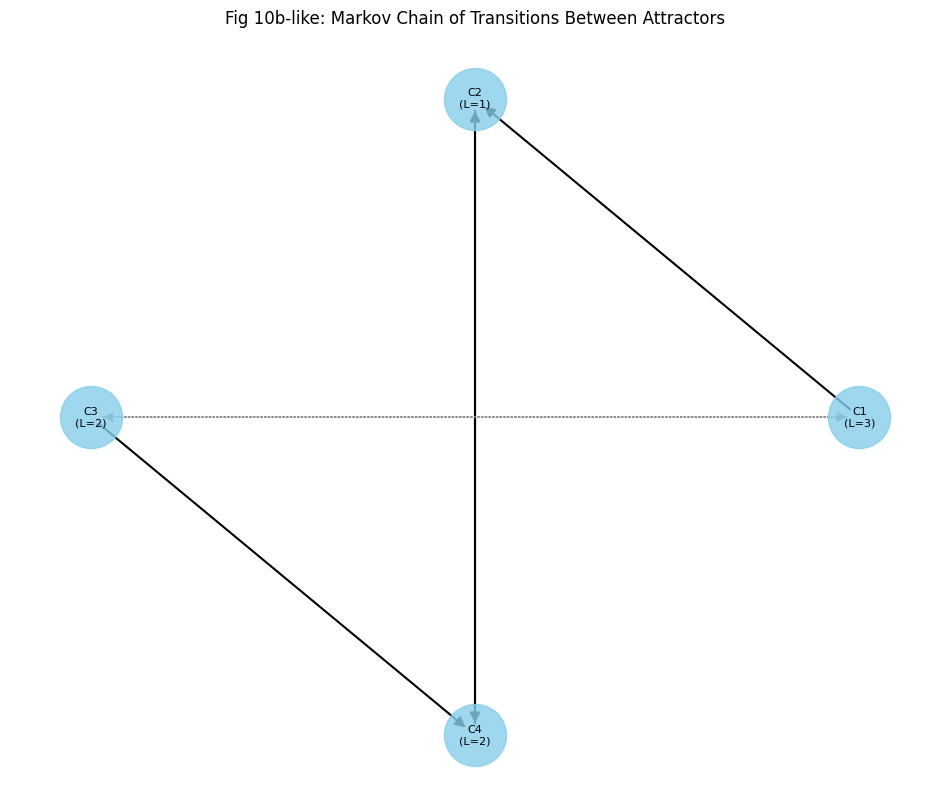

In [3]:
import matplotlib.pyplot as plt
import networkx as nx # You might need to install: pip install networkx
from collections import Counter, defaultdict

# --- Assume you have run Fig 9 simulation for ONE network instance ---
# And have these variables from that run:
# attractors_list: A list of canonical cycle representations (the nodes)
# all_source_dest_probs: A list of dictionaries, where each dict is for a source attractor
#                        e.g., all_source_dest_probs[source_idx][dest_idx] = probability

# ---- MOCK DATA for Fig 10 (Replace with actual data from your Fig 9 run) ----
# Let's say your Fig 9 run for one net (N=30, K=2, No Taut/Cont) yielded:
# attractors_list_fig10 = [cycle1_repr, cycle2_repr, cycle3_repr, cycle4_repr] # Canonical representations
# For example:
c1 = ((0,0,1),(0,1,0),(1,0,0)) # Cycle 1 (length 3) - made up
c2 = ((1,1,1),)                # Cycle 2 (length 1) - made up
c3 = ((0,0,0),(1,1,0))        # Cycle 3 (length 2) - made up
c4 = ((1,0,1),(0,1,1))        # Cycle 4 (length 2) - made up
attractors_list_fig10 = [c1, c2, c3, c4] # These are tuples of tuples

# transition_probs_fig10[source_attractor_canonical_repr][dest_attractor_canonical_repr] = probability
transition_probs_fig10 = defaultdict(lambda: defaultdict(float))
# Example: From c1, 80% to c1, 10% to c2, 10% to c3
transition_probs_fig10[c1][c1] = 0.80 # Probability of returning to itself
transition_probs_fig10[c1][c2] = 0.10
transition_probs_fig10[c1][c3] = 0.10
# From c2, 90% to c2, 10% to c4
transition_probs_fig10[c2][c2] = 0.90
transition_probs_fig10[c2][c4] = 0.10
# From c3, 5% to c1, 85% to c3, 10% to c4
transition_probs_fig10[c3][c1] = 0.05
transition_probs_fig10[c3][c3] = 0.85
transition_probs_fig10[c3][c4] = 0.10
# From c4, 95% to c4, 5% to c2
transition_probs_fig10[c4][c4] = 0.95
transition_probs_fig10[c4][c2] = 0.05

# You would get this from your Fig 9 code:
# For each source_cycle_idx, source_cycle_canonical in enumerate(attractors_list):
#   dest_counts = destination_cycle_counts_for_this_source
#   total_perturbations = total_perturbations_for_this_source
#   for dest_attractor_canonical, count in dest_counts.items():
#       prob = count / total_perturbations if total_perturbations > 0 else 0
#       transition_probs_fig10[source_cycle_canonical][dest_attractor_canonical] = prob
# ---- END MOCK DATA ----

if not transition_probs_fig10 or not attractors_list_fig10:
    print("No transition probability data or attractors list provided for Figure 10. Skipping.")
else:
    G = nx.DiGraph()

    # Map canonical representations to short node labels (e.g., "C1", "C2")
    node_labels = {attractor: f"C{i+1}\n(L={len(attractor)})" for i, attractor in enumerate(attractors_list_fig10)}

    for attractor in attractors_list_fig10:
        G.add_node(node_labels[attractor])

    # Add edges based on probabilities
    # Paper shows: solid for most probable (other than self), dotted for second most probable
    for source_can, dest_map in transition_probs_fig10.items():
        source_label = node_labels[source_can]

        # Get transitions to *other* cycles, sorted by probability
        other_transitions = []
        for dest_can, prob in dest_map.items():
            if dest_can != source_can and prob > 0.001: # Kauffman used 0.01 for Fig 9b
                other_transitions.append((prob, dest_can))

        other_transitions.sort(key=lambda x: x[0], reverse=True)

        if other_transitions:
            # Most probable
            prob_most, dest_most_can = other_transitions[0]
            dest_most_label = node_labels[dest_most_can]
            G.add_edge(source_label, dest_most_label, weight=prob_most, style='solid', color='black')

            # Second most probable
            if len(other_transitions) > 1:
                prob_second, dest_second_can = other_transitions[1]
                dest_second_label = node_labels[dest_second_can]
                G.add_edge(source_label, dest_second_label, weight=prob_second, style='dotted', color='gray')

    plt.figure(figsize=(12, 10))
    # pos = nx.spring_layout(G, k=0.5, iterations=50) # k adjusts spacing
    pos = nx.circular_layout(G) # Or circular_layout, kamada_kawai_layout etc.

    nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='skyblue', alpha=0.8)
    nx.draw_networkx_labels(G, pos, font_size=8)

    solid_edges = [(u,v) for (u,v,d) in G.edges(data=True) if d.get('style') == 'solid']
    dotted_edges = [(u,v) for (u,v,d) in G.edges(data=True) if d.get('style') == 'dotted']

    nx.draw_networkx_edges(G, pos, edgelist=solid_edges, width=1.5, arrowsize=15, edge_color='black', style='solid')
    nx.draw_networkx_edges(G, pos, edgelist=dotted_edges, width=1.0, arrowsize=15, edge_color='gray', style='dotted')

    edge_labels = {(u,v): f"{d['weight']:.2f}" for u,v,d in G.edges(data=True) if 'weight' in d}
    # nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7) # Can get cluttered

    plt.title("Fig 10b-like: Markov Chain of Transitions Between Attractors")
    plt.axis('off')
    plt.show()

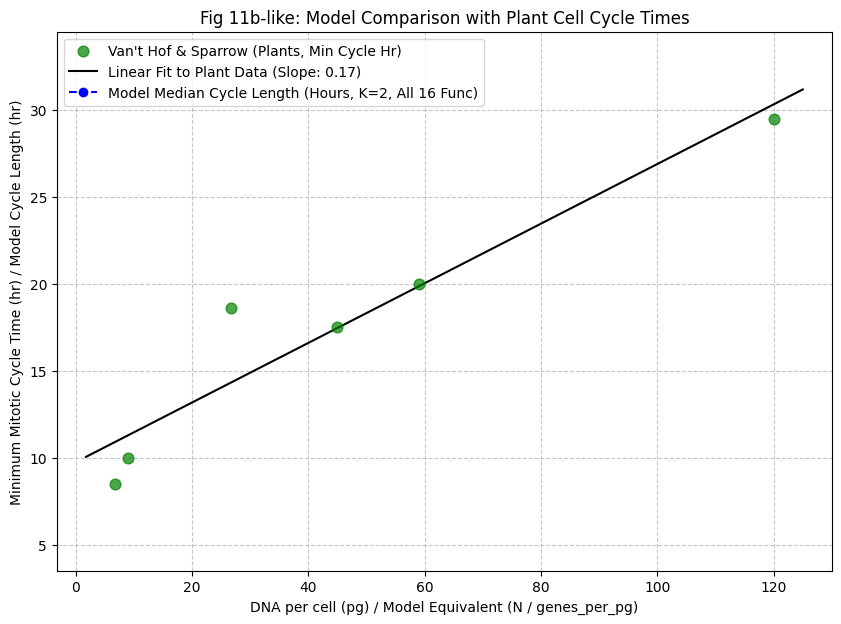

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# --- ASSUME THESE VARIABLES ARE PRE-POPULATED FROM PREVIOUS SIMULATIONS/DATA ENTRY ---
# Example:
# fig11a_plant_data_raw = {
#     "Trillium erectum": (120, 29.5), "Tulipa kaufmanniana": (59, 20.0),
#     "Tradescantia paludosa": (45, 17.5), "Vicia faba": (26.7, 18.6),
#     "Pisum sativum": (9.0, 10.0), "Helianthus annus": (6.8, 8.5)
# } # (DNA_pg, MinMitoticCycle_hr)
# GENES_PER_PG = 500000
# median_cycle_lengths_all_func = [(10, 2.0), (20, 3.0), (40, 5.0), (80, 8.0), (100, 10.0), (150, 12.0), (200, 15.0)]
# # This list (N, median_cycle_length_in_minutes) should come from your Fig 4 simulation

# --- START: Data Transcription (if not done globally) ---
if 'fig11a_plant_data_raw' not in globals():
    fig11a_plant_data_raw = {
        "Trillium erectum": (120, 29.5), "Tulipa kaufmanniana": (59, 20.0),
        "Tradescantia paludosa": (45, 17.5), "Vicia faba": (26.7, 18.6),
        "Pisum sativum": (9.0, 10.0), "Helianthus annus": (6.8, 8.5)
    }
if 'GENES_PER_PG' not in globals():
    GENES_PER_PG = 500000 # Based on E.coli example: 2000 genes / 0.004 pg
if 'median_cycle_lengths_all_func' not in globals():
    # Placeholder - Replace with your actual Fig 4 simulation results for K=2 All 16 Func
    print("Warning: 'median_cycle_lengths_all_func' not found. Using placeholder data for Fig 11b.")
    median_cycle_lengths_all_func = [(10, 30), (20,45), (50,90), (100,150), (200,240), (400,360), (800,500), (1000,600), (2000, 800)] # (N, median_minutes)
# --- END: Data Transcription ---


plt.figure(figsize=(10, 7))

# Plot Van't Hof & Sparrow data (linear scale)
plant_dna_pg_list = []
plant_cycle_hr_list = []
if fig11a_plant_data_raw:
    for org, data_tuple in fig11a_plant_data_raw.items():
        plant_dna_pg_list.append(data_tuple[0])
        plant_cycle_hr_list.append(data_tuple[1])

    if plant_dna_pg_list:
        plt.scatter(plant_dna_pg_list, plant_cycle_hr_list, color='green',
                    label="Van't Hof & Sparrow (Plants, Min Cycle Hr)", s=60, alpha=0.7, zorder=10)

        # Plot the line from their paper (fit to their data)
        if len(plant_dna_pg_list) >= 2:
            slope_bio_plant, intercept_bio_plant = np.polyfit(plant_dna_pg_list, plant_cycle_hr_list, 1)
            line_x_vh_fit = np.array([min(plant_dna_pg_list)-5 if plant_dna_pg_list else 0, max(plant_dna_pg_list)+5 if plant_dna_pg_list else 120])
            line_y_vh_fit = slope_bio_plant * line_x_vh_fit + intercept_bio_plant
            plt.plot(line_x_vh_fit, line_y_vh_fit, 'k-',
                     label=f"Linear Fit to Plant Data (Slope: {slope_bio_plant:.2f})", zorder=5)
else:
    print("Warning: fig11a_plant_data_raw is empty.")


# Plot model data (Median Cycle Length in Hours)
# Convert model N (genes) to DNA_pg for x-axis
# Convert model cycle length (minutes) to hours for y-axis
if median_cycle_lengths_all_func and GENES_PER_PG > 0:
    # Filter for positive N and cycle lengths
    model_N_fig11 = np.array([d[0] for d in median_cycle_lengths_all_func if d[0] > 0 and d[1] > 0])
    model_cycles_min_fig11 = np.array([d[1] for d in median_cycle_lengths_all_func if d[0] > 0 and d[1] > 0])

    if model_N_fig11.size > 0:
        model_dna_pg_fig11 = model_N_fig11 / GENES_PER_PG
        model_cycles_hr_fig11 = model_cycles_min_fig11 / 60.0

        plt.plot(model_dna_pg_fig11, model_cycles_hr_fig11,
                 marker='o', linestyle='--', color='blue',
                 label="Model Median Cycle Length (Hours, K=2, All 16 Func)")
    else:
        print("Warning: No valid model data (N>0, cycle_len>0) to plot for Fig 11b.")
else:
    print("Warning: 'median_cycle_lengths_all_func' or 'GENES_PER_PG' missing or invalid for Fig 11b model data.")

plt.xlabel("DNA per cell (pg) / Model Equivalent (N / genes_per_pg)")
plt.ylabel("Minimum Mitotic Cycle Time (hr) / Model Cycle Length (hr)")
plt.title("Fig 11b-like: Model Comparison with Plant Cell Cycle Times")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)

# Set plot limits based on the range of plant data if available
if plant_dna_pg_list and plant_cycle_hr_list:
    plt.xlim(left=min(plant_dna_pg_list) - 10 if plant_dna_pg_list else -5,
             right=max(plant_dna_pg_list) + 10 if plant_dna_pg_list else 130)
    plt.ylim(bottom=min(plant_cycle_hr_list) - 5 if plant_cycle_hr_list else -2,
             top=max(plant_cycle_hr_list) + 5 if plant_cycle_hr_list else 35)
else: # Default limits if no plant data
    plt.xlim(left=-5, right=130)
    plt.ylim(bottom=-2, top=35)
plt.show()

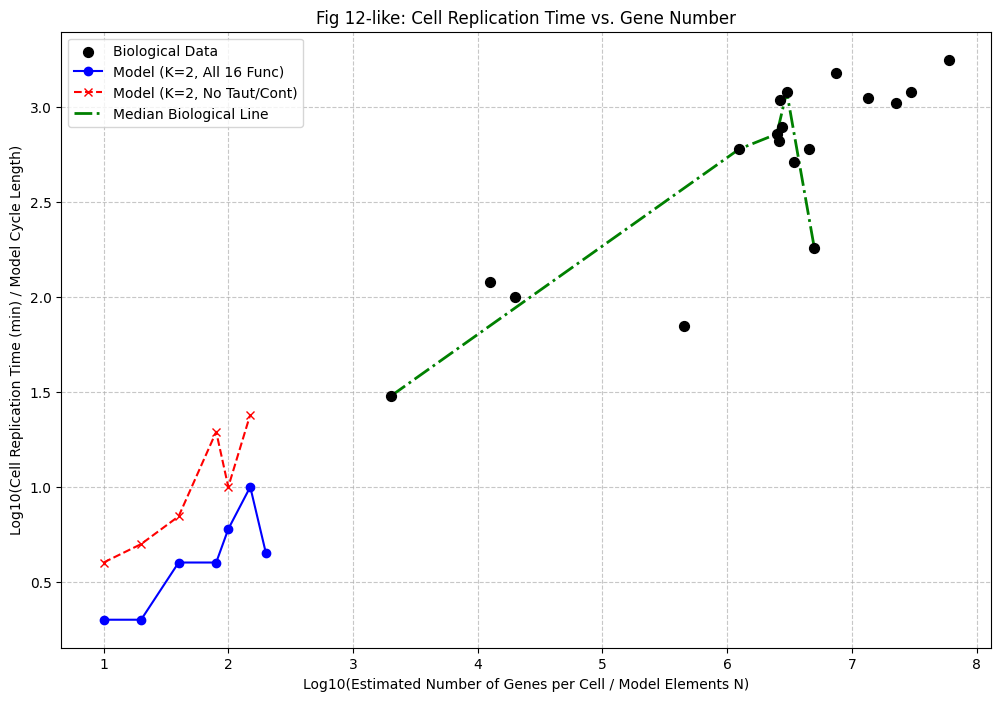

In [10]:
# Data from Table 1 (Fig 12: Cell Replication Time)
# (Organism, Approx DNA pg (10^-12g), Replication Time (min))
# DNA needs to be converted to estimated gene number.
# Kauffman: 2x10^6 genes = 6x10^-12 g DNA => 1 pg DNA = (2/6)x10^6 genes = 0.333 x 10^6 genes
DNA_TO_GENES_FACTOR = (2e6 / 6e-12) # genes per gram
PG_TO_G = 1e-12 # picograms to grams

# (Organism, DNA_pg, RepTime_min) - Partial list from Table 1 / Fig 12 context
# You need to be careful with DNA content units and gene estimation.
# Watson (1965) for E.coli: 0.004 pg DNA, 2000 genes. This is a key reference.
# So, 2000 genes / 0.004 pg = 500,000 genes/pg. Let's use this for consistency if possible.
GENES_PER_PG = 500000 # Based on E.coli example

fig12_bio_data_raw = {
    "Bacteria (E.coli)": {"dna_pg": 0.004, "rep_time_min": 30}, # Watson 1965
    "Protozoa (Tetrahymena)": {"dna_pg": 10, "rep_time_min": 180}, # Nanney & Rudzinska, Altman&Dittmer
    "Yeast (Saccharomyces)": {"dna_pg": 0.025, "rep_time_min": 120}, # Horowitz & Metzenberg, Williamson
    "Aspergillus": {"dna_pg": 0.04, "rep_time_min": 100}, # Horowitz & Metzenberg, Rosenberger&Kessel (approx)
    "Sea urchin": {"dna_pg": 0.9, "rep_time_min": 70}, # Sparrow & Evans, Mazia
    "Chicken": {"dna_pg": 2.5, "rep_time_min": 600}, # Vendrely, Cleaver
    "Mouse": {"dna_pg": 5.0, "rep_time_min": 720}, # Vendrely, Cleaver
    "Rat": {"dna_pg": 5.2, "rep_time_min": 660}, # Vendrely, Cleaver
    "Man": {"dna_pg": 6.0, "rep_time_min": 1200}, # Vendrely, Cleaver
    "Rabbit": {"dna_pg": 5.5, "rep_time_min": 780},
    "Dog": {"dna_pg": 5.3, "rep_time_min": 1080},
    "Frog": {"dna_pg": 15.0, "rep_time_min": 1500},
    # Plants from Van't Hof & Sparrow (1963) - min rep times
    "Vicia faba": {"dna_pg": 26.7, "rep_time_min": 18.6 * 60}, # DNA from Fig11a scale (need conversion)
    "Pisum sativum": {"dna_pg": 9.0, "rep_time_min": 10.0 * 60}, # DNA from Fig11a scale
    # ... more plant data
}
# For plants in Fig 11a, DNA is given in 10^-12g (pg). Times are in hours.
fig11a_plant_data_raw = { # (Name, DNA_pg, MinMitoticCycle_hr) from Fig 11a
    "Trillium erectum": (120, 29.5),
    "Tulipa kaufmanniana": (59, 20.0), # Assuming label order
    "Tradescantia paludosa": (45, 17.5),
    "Vicia faba": (26.7, 18.6), # Matches!
    "Pisum sativum": (9.0, 10.0),
    "Helianthus annus": (6.8, 8.5),
}


fig12_plot_data = []
for org, data in fig12_bio_data_raw.items():
    est_genes = data["dna_pg"] * GENES_PER_PG
    fig12_plot_data.append({"organism": org, "genes": est_genes, "rep_time": data["rep_time_min"]})

for org, (dna_pg, time_hr) in fig11a_plant_data_raw.items():
     if org not in fig12_bio_data_raw: # Avoid double counting if Vicia, Pisum are there
        est_genes = dna_pg * GENES_PER_PG
        fig12_plot_data.append({"organism": org + " (min)", "genes": est_genes, "rep_time": time_hr * 60})


# Data from Table 2 (Fig 13: Number of Cell Types)
fig13_bio_data_raw = { # (Organism, Approx DNA pg, Num Cell Types)
    "Bacteria": {"dna_pg": 0.004, "num_types": 2},
    "Algae (Chlamydomonas)": {"dna_pg": 0.1, "num_types": 5}, # Horowitz & Metzenberg for DNA
    "Saccharomyces": {"dna_pg": 0.025, "num_types": 2}, # Guessing cell types not explicitly listed
    "Neurospora crassa": {"dna_pg": 0.04, "num_types": 5},
    "Sponge": {"dna_pg": 0.1, "num_types": 13}, # DNA Sparrow & Evans (similar to algae)
    "Hydra": {"dna_pg": 0.5, "num_types": 14}, # DNA between sponge and jellyfish
    "Jellyfish": {"dna_pg": 0.7, "num_types": 25}, # DNA Sparrow & Evans
    "Annelid worm": {"dna_pg": 1.0, "num_types": 57}, # Approx DNA
    "Man": {"dna_pg": 6.0, "num_types": 100}, # Vendrely DNA
}
fig13_plot_data = []
for org, data in fig13_bio_data_raw.items():
    est_genes = data["dna_pg"] * GENES_PER_PG
    fig13_plot_data.append({"organism": org, "genes": est_genes, "num_types": data["num_types"]})

# --- Plotting Figure 12 (Cell Replication Time vs. Gene Number) ---
# Needs:
# 1. fig12_plot_data (biological)
# 2. median_cycle_lengths_all_func (model data from Fig 4 sim, K=2, all 16)
# 3. median_cycle_lengths_no_const (model data from Fig 4 sim, K=2, 14 func)
# Assuming 1 model state transition = 1 minute (Kauffman's assumption)

plt.figure(figsize=(12, 8))

# Plot biological data
bio_genes = [d["genes"] for d in fig12_plot_data]
bio_rep_times = [d["rep_time"] for d in fig12_plot_data]
plt.scatter(np.log10(bio_genes), np.log10(bio_rep_times), color='black', label="Biological Data", s=50, zorder=10)
# for i, d in enumerate(fig12_plot_data): # Optional: label points
#     plt.text(np.log10(d["genes"])+0.05, np.log10(d["rep_time"]), d["organism"].split(" ")[0], fontsize=7)

# Plot model data (All 16 functions) - from Fig 4
if 'median_cycle_lengths_all_func' in globals() and median_cycle_lengths_all_func:
    model_N_all = [d[0] for d in median_cycle_lengths_all_func if d[1]>0] # N is number of "genes"
    model_cycles_all = [d[1] for d in median_cycle_lengths_all_func if d[1]>0] # Median cycle length (minutes)
    if model_N_all:
        plt.plot(np.log10(model_N_all), np.log10(model_cycles_all), marker='o', linestyle='-', color='blue', label="Model (K=2, All 16 Func)")

# Plot model data (14 functions, no const) - from Fig 4
if 'median_cycle_lengths_no_const' in globals() and median_cycle_lengths_no_const:
    model_N_no_const = [d[0] for d in median_cycle_lengths_no_const if d[1]>0]
    model_cycles_no_const = [d[1] for d in median_cycle_lengths_no_const if d[1]>0]
    if model_N_no_const:
        plt.plot(np.log10(model_N_no_const), np.log10(model_cycles_no_const), marker='x', linestyle='--', color='red', label="Model (K=2, No Taut/Cont)")

# Median line for biological data (as in paper) - select key points
median_bio_points_names = ["Bacteria (E.coli)", "Protozoa (Tetrahymena)", "Chicken", "Mouse", "Man"] #Kauffman's median line points
median_bio_genes = []
median_bio_times = []
for d in fig12_plot_data:
    if d["organism"] in median_bio_points_names:
        median_bio_genes.append(d["genes"])
        median_bio_times.append(d["rep_time"])
# Sort them by gene number before plotting line
sorted_median_points = sorted(zip(median_bio_genes, median_bio_times))
if sorted_median_points:
    sorted_genes = [p[0] for p in sorted_median_points]
    sorted_times = [p[1] for p in sorted_median_points]
    plt.plot(np.log10(sorted_genes), np.log10(sorted_times), color='green', linestyle='-.', linewidth=2, label="Median Biological Line")


plt.xlabel("Log10(Estimated Number of Genes per Cell / Model Elements N)")
plt.ylabel("Log10(Cell Replication Time (min) / Model Cycle Length)")
plt.title("Fig 12-like: Cell Replication Time vs. Gene Number")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.show()






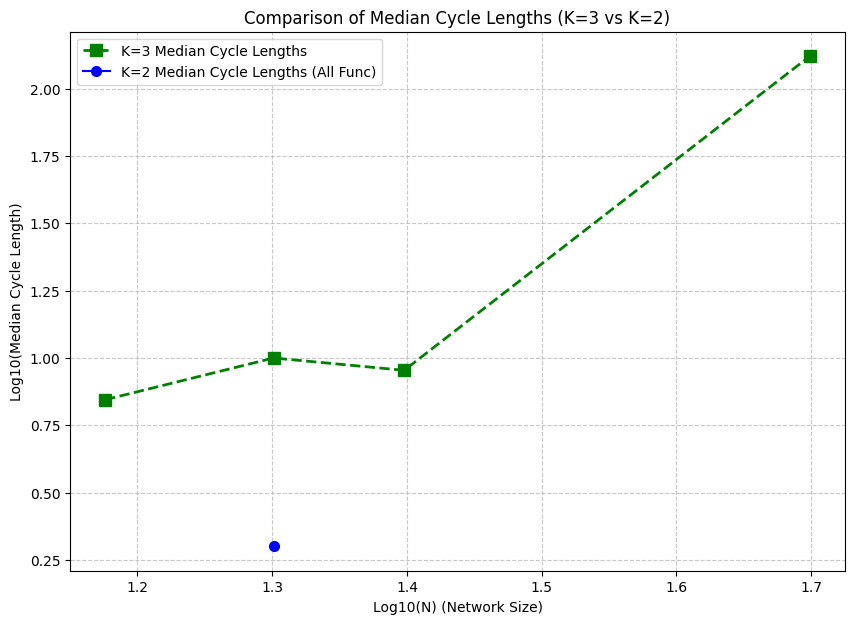

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# --- ASSUME THESE VARIABLES ARE PRE-POPULATED FROM PREVIOUS SIMULATIONS ---
# Example:
# k3_median_cycle_lengths = [(15, 7.0), (20, 10.0), (25, 12.0), (50, 22.0)]
# # (N, median_cycle_length_for_K3)
# median_cycle_lengths_all_func = [(10, 2.0), (15,2.5), (20, 3.0), (25,3.5), (40, 5.0), (50, 6.0)]
# # (N, median_cycle_length_for_K2_All_Func)

# --- START: Placeholder data (if not run) ---
if 'k3_median_cycle_lengths' not in globals():
    print("Warning: 'k3_median_cycle_lengths' not found. Using placeholder data.")
    k3_median_cycle_lengths = [(15, 10), (25, 18), (50, 40)] # (N, median_len_k3)
if 'median_cycle_lengths_all_func' not in globals():
    print("Warning: 'median_cycle_lengths_all_func' (K=2 data) not found. Using placeholder data.")
    median_cycle_lengths_all_func = [(10,2), (15,3), (20,4), (25,5), (40,7), (50,9)] # (N, median_len_k2_all)
# --- END: Placeholder data ---

plt.figure(figsize=(10, 7))

# Plot K=3 data
if k3_median_cycle_lengths:
    # Filter for N > 0 and median_len > 0
    ns_k3 = np.array([d[0] for d in k3_median_cycle_lengths if d[0] > 0 and d[1] > 0])
    lengths_k3 = np.array([d[1] for d in k3_median_cycle_lengths if d[0] > 0 and d[1] > 0])

    if ns_k3.size > 0:
        plt.plot(np.log10(ns_k3), np.log10(lengths_k3),
                 marker='s', markersize=8, linestyle='--', linewidth=2, color='green', label="K=3 Median Cycle Lengths")
    else:
        print("Warning: No valid K=3 data to plot after filtering.")
else:
    print("Warning: 'k3_median_cycle_lengths' is empty.")
    ns_k3 = np.array([]) # Ensure ns_k3 exists for K2 data filtering

# Plot K=2 data for comparison, aligning N values with K=3
if median_cycle_lengths_all_func:
    k2_comparison_N = []
    k2_comparison_lengths = []
    # Create a lookup dictionary for K=2 data for efficient access
    k2_data_dict = {n_val: l_val for n_val, l_val in median_cycle_lengths_all_func if n_val > 0 and l_val > 0}

    # Use N values from K=3 simulation if available, otherwise use N from K=2 data
    n_values_to_check = ns_k3 if ns_k3.size > 0 else sorted(list(k2_data_dict.keys()))

    for n_val_check in n_values_to_check:
        if n_val_check in k2_data_dict: # Check if K=2 data exists for this N
            k2_comparison_N.append(n_val_check)
            k2_comparison_lengths.append(k2_data_dict[n_val_check])

    if k2_comparison_N:
        # Sort by N for cleaner plotting if n_values_to_check wasn't sorted (ns_k3 might not be)
        sorted_indices = np.argsort(k2_comparison_N)
        sorted_k2_N = np.array(k2_comparison_N)[sorted_indices]
        sorted_k2_lengths = np.array(k2_comparison_lengths)[sorted_indices]

        plt.plot(np.log10(sorted_k2_N), np.log10(sorted_k2_lengths),
                 marker='o', markersize=7, linestyle='-', linewidth=1.5, color='blue', label="K=2 Median Cycle Lengths (All Func)")
    else:
        print("Warning: No K=2 data to plot or no K=2 data for N values corresponding to K=3 simulation.")
else:
    print("Warning: 'median_cycle_lengths_all_func' (K=2 data) is empty.")

plt.xlabel("Log10(N) (Network Size)")
plt.ylabel("Log10(Median Cycle Length)")
plt.title("Comparison of Median Cycle Lengths (K=3 vs K=2)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.show()

Fitted slope for model data on Fig 13: 0.494 (Paper's Fig 13 model slope ~0.5)


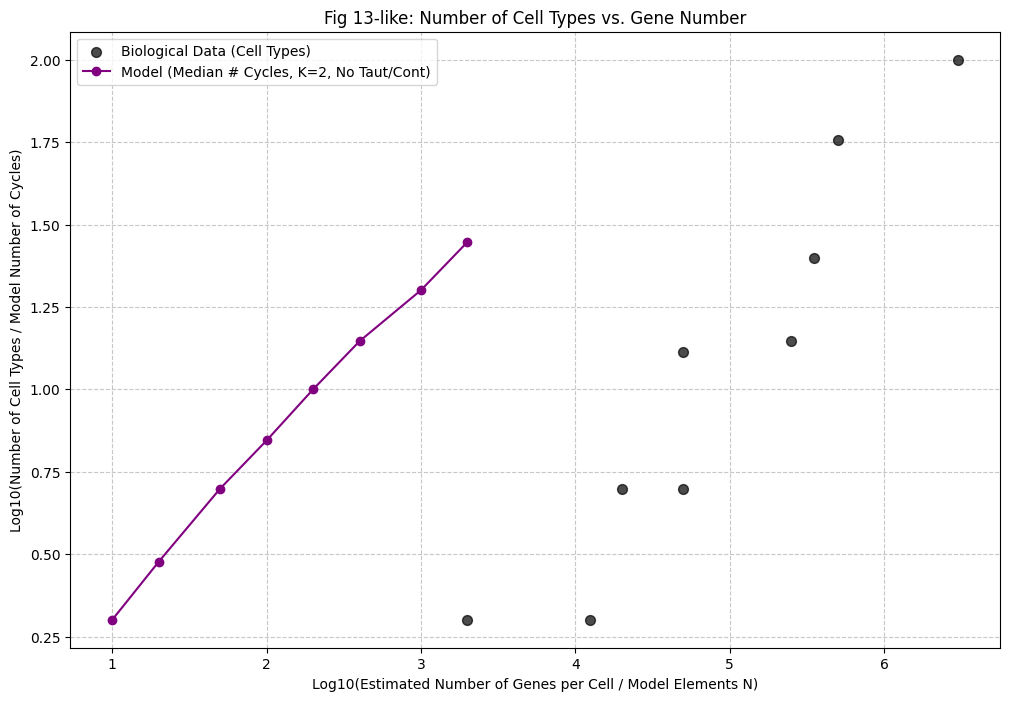

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# --- ASSUME THESE VARIABLES ARE PRE-POPULATED ---
# Example:
# GENES_PER_PG = 500000
# fig13_bio_data_raw = {
#     "Bacteria": {"dna_pg": 0.004, "num_types": 2},
#     "Algae": {"dna_pg": 0.1, "num_types": 5}, # ... more data
# }
# median_cycles_per_N = [(10, 2.0), (20, 3.0), (40, 4.0), (100, 6.0), (200, 8.0), (400, 10.0)]
# # (N, median_num_distinct_cycles) from your Fig 7 simulation (K=2, No Taut/Cont)

# --- START: Data Transcription (if not done globally) ---
if 'GENES_PER_PG' not in globals():
    GENES_PER_PG = 500000
if 'fig13_bio_data_raw' not in globals():
    fig13_bio_data_raw = {
        "Bacteria": {"dna_pg": 0.004, "num_types": 2}, "Algae": {"dna_pg": 0.1, "num_types": 5},
        "Saccharomyces": {"dna_pg": 0.025, "num_types": 2}, "Neurospora": {"dna_pg": 0.04, "num_types": 5},
        "Sponge": {"dna_pg": 0.1, "num_types": 13}, "Hydra": {"dna_pg": 0.5, "num_types": 14},
        "Jellyfish": {"dna_pg": 0.7, "num_types": 25}, "Annelid": {"dna_pg": 1.0, "num_types": 57},
        "Man": {"dna_pg": 6.0, "num_types": 100},
    }
if 'median_cycles_per_N' not in globals():
    print("Warning: 'median_cycles_per_N' not found. Using placeholder data for Fig 13.")
    median_cycles_per_N = [(10,2), (20,3), (50,5), (100,7), (200,10), (400,14), (1000,20), (2000,28)] # (N, median_num_cycles)
# --- END: Data Transcription ---

fig13_plot_data = []
if fig13_bio_data_raw and GENES_PER_PG > 0:
    for org, data in fig13_bio_data_raw.items():
        if data["dna_pg"] > 0 and data["num_types"] > 0: # Ensure log can be taken
            est_genes = data["dna_pg"] * GENES_PER_PG
            if est_genes > 0:
                 fig13_plot_data.append({"organism": org, "genes": est_genes, "num_types": data["num_types"]})

plt.figure(figsize=(12, 8))

# Plot biological data
if fig13_plot_data:
    bio_genes_f13 = np.array([d["genes"] for d in fig13_plot_data])
    bio_num_types = np.array([d["num_types"] for d in fig13_plot_data])

    plt.scatter(np.log10(bio_genes_f13), np.log10(bio_num_types),
                color='black', label="Biological Data (Cell Types)", s=50, zorder=10, alpha=0.7)
else:
    print("Warning: No valid biological data to plot for Fig 13.")

# Plot model data (Median Number of Cycles from Fig 7)
if median_cycles_per_N:
    # Filter for N > 0 and median_num_cycles > 0 for log plot
    model_N_fig7 = np.array([d[0] for d in median_cycles_per_N if d[0] > 0 and d[1] > 0])
    model_num_cycles_fig7 = np.array([d[1] for d in median_cycles_per_N if d[0] > 0 and d[1] > 0])

    if model_N_fig7.size > 0:
        plt.plot(np.log10(model_N_fig7), np.log10(model_num_cycles_fig7),
                 marker='o', linestyle='-', color='purple',
                 label="Model (Median # Cycles, K=2, No Taut/Cont)")

        # Optional: Fit a line to model data to see its slope
        if len(model_N_fig7) >= 2:
            slope_model_f13, _ = np.polyfit(np.log10(model_N_fig7), np.log10(model_num_cycles_fig7), 1)
            print(f"Fitted slope for model data on Fig 13: {slope_model_f13:.3f} (Paper's Fig 13 model slope ~0.5)")
else:
    print("Warning: 'median_cycles_per_N' (model data for Fig 13) is empty.")

plt.xlabel("Log10(Estimated Number of Genes per Cell / Model Elements N)")
plt.ylabel("Log10(Number of Cell Types / Model Number of Cycles)")
plt.title("Fig 13-like: Number of Cell Types vs. Gene Number")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.show()